# LDPC: как избыточность вытаскивает биты из шума

Передаём $k$ информационных бит в $n>k$ канальных символах, скорость $R=k/n$. Любое кодовое слово $\mathbf c$ удовлетворяет $m=n-k$ проверкам чётности:
$$H\,\mathbf c^T=\mathbf 0 \pmod 2$$
$H$ — **разреженная** (Low-Density Parity-Check): в каждом столбце $d_v$ единиц, в каждой строке $d_c$. Здесь регулярный код Галлагера $(d_v,d_c)=(3,6)$, $R=1-d_v/d_c=1/2$.

**Канал.** BPSK $x=1-2c$, $y=x+n$, $n\sim\mathcal N(0,\sigma^2)$, $\sigma^2=\dfrac{1}{2R\,E_b/N_0}$. Приёмник не режет $y$ по знаку, а считает логарифм отношения правдоподобия:
$$L_\text{ch}=\ln\frac{P(c=0\,|\,y)}{P(c=1\,|\,y)}=\frac{2y}{\sigma^2}$$
Знак — решение, модуль — уверенность. Для $x=+1$: $L_\text{ch}\sim\mathcal N(\mu,\,2\mu)$, $\mu=2/\sigma^2$ — один параметр описывает всё.

**Декодер** — обмен сообщениями по графу Таннера (биты ↔ проверки), belief propagation:
- бит → проверке: $L_{v\to c}=L_\text{ch}+\sum_{c'\ne c}L_{c'\to v}$ — независимые свидетельства **складываются**;
- проверка → биту: $\tanh\dfrac{L_{c\to v}}{2}=\prod_{v'\ne v}\tanh\dfrac{L_{v'\to c}}{2}$ — бит равен XOR остальных, а XOR **не надёжнее самого слабого** из них. Упрощение min-sum: $L_{c\to v}\approx\alpha\prod\operatorname{sign}\cdot\min|L|$.

Через $\ell$ итераций в решение по биту вносят вклад до $[(d_v-1)(d_c-1)]^\ell$ других символов. **Шум у них независимый, а ограничения общие** — то же усреднение, что в деспрединге CDMA, но избыточность всего $1/R=2$, а не $N=1023$.

**Пределы при $R=1/2$:** Шеннон для BPSK — $E_b/N_0>0.19$ дБ; порог регулярного (3,6) — ≈1.1 дБ; без кода BER $10^{-5}$ стоит 9.6 дБ. Оптимизированные нерегулярные LDPC (DVB-S2, Wi-Fi, 5G NR) — в 0.1–0.5 дБ от Шеннона.


**Как устроен ноутбук.**
- *Часть I — устройство по шагам* (разделы 1–9): на игрушечных кодах из 7–24 бит разворачиваем каждую деталь — что такое проверка чётности и синдром, как строится $H$, откуда берутся циклы, как кодировать над GF(2), откуда формула LLR, почему узел-проверка считает через $\tanh$, зачем «экстринсик», и прогоняем BP вручную с распечаткой каждого сообщения.
- *Часть II — код длиной 1008 в деле* (разделы 10–16): итерации изнутри, гауссово приближение и EXIT-порог, плотностная эволюция, расписания декодера, водопад BER/FER, влияние длины кода и нормировки min-sum.

Параметры — в ячейке ниже, всё остальное перезапускается от них.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc
from scipy.optimize import brentq


%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
N_CODE = 1008      # длина кодового слова (кратна DC)
DV, DC = 3, 6      # бит входит в DV проверок, проверка охватывает DC бит → R = 1 − DV/DC
EBN0_DB = 1.5      # рабочая точка для разделов 2–4 (порог (3,6) ≈ 1.1 дБ)
MAX_ITER = 50
ALPHA_MS = 0.8     # нормировка min-sum

rng = np.random.default_rng(SEED)

## Примитивы: матрица H, кодер над GF(2), BP-декодер, канал, J-функция
Всё, что используется ниже, — в одной ячейке. Что где разбирается подробно:

| функция | что делает | раздел |
|---|---|---|
| `gallager_H`, `count_4cycles` | построение регулярной $H$, удаление 4-циклов | 2, 3 |
| `gf2_rref`, `LDPC.encode` | метод Гаусса над GF(2), систематический кодер | 4 |
| `channel` | BPSK + AWGN, LLR канала $2y/\sigma^2$ | 5 |
| `boxplus`, `check_update`, `loo_prod` | узел-проверка: $\tanh$-правило и min-sum | 6, 9 |
| `LDPC.decode` | BP: flooding / layered, флаг `extrinsic` | 7–10, 14 |
| `LDPC.bitflip` | жёсткий декодер Галлагера (для сравнения) | 15 |
| `mi`, `J`, `exit_v`, `exit_c`, `de_traj` | взаимная информация, EXIT, порог | 11, 12 |

In [2]:
def gallager_H(n, dv, dc, rng, fix_4cycles=True, max_fix=20000):
    """Регулярная (dv,dc) матрица Галлагера: dv полос, каждая — перестановка столбцов базовой."""
    mb = n // dc
    base = np.zeros((mb, n), np.int32)
    for i in range(mb):
        base[i, i * dc:(i + 1) * dc] = 1
    perms = [np.arange(n)] + [rng.permutation(n) for _ in range(dv - 1)]
    build = lambda: np.vstack([base[:, p] for p in perms])
    H = build()
    for _ in range(max_fix if fix_4cycles else 0):
        Hf = H.astype(np.float32)
        O = np.triu(Hf @ Hf.T, 1)
        bad = np.argwhere(O > 1)                  # две проверки делят ≥2 бита → 4-цикл
        if len(bad) == 0:
            break
        r1, r2 = bad[rng.integers(len(bad))]
        j = rng.choice(np.nonzero(H[r1] & H[r2])[0])
        b, k = r2 // mb, rng.integers(n)          # r2 в полосе ≥1: строки одной полосы не пересекаются
        perms[b][[j, k]] = perms[b][[k, j]]
        H = build()
    return H


def count_4cycles(H):
    Hf = H.astype(np.float32)
    O = np.triu(Hf @ Hf.T, 1).astype(np.int64)
    return int(np.sum(O * (O - 1) // 2))


def gf2_rref(H):
    """Приведение H к ступенчатому виду над GF(2). Возвращает A, столбцы-пивоты (проверочные биты), остальные (информационные)."""
    A = H.astype(np.uint8).copy()
    m, n = A.shape
    piv, r = [], 0
    for c in range(n):
        if r == m:
            break
        nz = np.nonzero(A[r:, c])[0]
        if len(nz) == 0:
            continue
        p = r + nz[0]
        A[[r, p]] = A[[p, r]]
        rows = np.nonzero(A[:, c])[0]
        A[rows[rows != r]] ^= A[r]
        piv.append(c)
        r += 1
    return A[:r], np.array(piv), np.setdiff1d(np.arange(n), piv)


def loo_prod(t):
    """Произведение по последней оси «всех, кроме себя» — через префиксы и суффиксы (без деления на ~0)."""
    one = np.ones_like(t[..., :1])
    pre = np.cumprod(np.concatenate([one, t[..., :-1]], -1), -1)
    suf = np.cumprod(np.concatenate([one, t[..., :0:-1]], -1), -1)[..., ::-1]
    return pre * suf


def boxplus(*Ls):
    """L1 ⊞ L2 ⊞ … — LLR от XOR независимых бит: tanh(L/2) перемножаются."""
    t = np.prod([np.tanh(np.clip(L, -40, 40) / 2) for L in np.broadcast_arrays(*Ls)], 0)
    return 2 * np.arctanh(np.clip(t, -1 + 1e-12, 1 - 1e-12))


def check_update(Lvc, algo="spa", alpha=0.8):
    """Узел-проверка: на последней оси dc входов, на выходе dc экстринсик-сообщений (каждое — без своего входа)."""
    if algo == "spa":
        t = loo_prod(np.tanh(np.clip(Lvc, -40, 40) / 2))
        return 2 * np.arctanh(np.clip(t, -1 + 1e-12, 1 - 1e-12))
    s = np.where(Lvc < 0, -1.0, 1.0)              # нормированный min-sum
    a = np.abs(Lvc)
    i1 = a.argmin(-1)[..., None]
    m1 = np.take_along_axis(a, i1, -1)
    np.put_along_axis(a, i1, np.inf, -1)
    m2 = a.min(-1, keepdims=True)                  # второй минимум — для самого минимального входа
    mag = np.where(np.arange(Lvc.shape[-1]) == i1, m2, m1)
    return alpha * s.prod(-1, keepdims=True) * s * mag


class LDPC:
    def __init__(self, H):
        self.H = H.astype(np.int32)
        self.Hf = H.astype(np.float32)            # float-матмул в BLAS: точен для малых целых и в разы быстрее int
        self.m, self.n = H.shape
        r, c = np.nonzero(H)                      # рёбра графа Таннера, упорядочены по проверкам
        self.E = len(c)
        self.ec, self.ev = r, c                   # проверка и бит на концах каждого ребра
        self.dc = self.E // self.m
        self.var = np.argsort(c, kind="stable").reshape(self.n, -1)   # рёбра каждого бита
        self.A, self.piv, self.info = gf2_rref(H)
        self.k = len(self.info)
        self.R = self.k / self.n
        self.P = self.A[:, self.info].astype(np.int32)
        # слои для layered-расписания: проверки внутри слоя не делят бит (у Галлагера слой = полоса)
        layers, used = [], []
        for i in range(self.m):
            for L, u in zip(layers, used):
                if not (u & H[i].astype(bool)).any():
                    L.append(i); u |= H[i].astype(bool); break
            else:
                layers.append([i]); used.append(H[i].astype(bool).copy())
        self.layers = [np.concatenate([np.arange(i * self.dc, (i + 1) * self.dc) for i in L]) for L in layers]

    def encode(self, U):
        C = np.zeros((U.shape[0], self.n), np.uint8)
        C[:, self.info] = U
        C[:, self.piv] = (U @ self.P.T) % 2       # строка i ступенчатой H: c[piv_i] = Σ A[i,info]·u
        return C

    def syndrome_ok(self, Ch):
        return ~((Ch.astype(np.float32) @ self.Hf.T) % 2).any(1)

    def decode(self, Lch, iters=50, algo="spa", alpha=0.8, cb=None, schedule="flood", extrinsic=True):
        """BP-декодер с ранним остановом: кадр с нулевым синдромом замораживается.
        schedule: "flood" — все проверки разом; "layered" — слой за слоем, следующий слой видит свежие LLR.
        extrinsic=False — ошибка нарочно: бит возвращает проверке её же сообщение («эхо»).
        cb(it, Lv, Lcv) — наблюдатель, получает все кадры на каждой итерации."""
        F = Lch.shape[0]
        Lv, Lcv = Lch.astype(float).copy(), np.zeros((F, self.E))
        n_it = np.full(F, iters)
        act = np.arange(F)                        # индексы ещё не сошедшихся кадров
        La = Lch.astype(float).copy()
        for it in range(iters + 1):
            if schedule == "flood":
                La = Lch[act] + Lcv[act][:, self.var].sum(-1)   # апостериорный LLR бита
            Lv[act] = La
            if cb is not None:
                cb(it, Lv, Lcv)
            ok = self.syndrome_ok((La < 0).astype(np.uint8))
            n_it[act[ok]] = it
            act, La = act[~ok], La[~ok]
            if len(act) == 0 or it == iters:
                break
            f, Lc = len(act), Lcv[act]
            if schedule == "flood":
                Lvc = La[:, self.ev] - (Lc if extrinsic else 0)          # бит → проверке (экстринсик)
                Lc = check_update(Lvc.reshape(f, self.m, self.dc), algo, alpha).reshape(f, self.E)
            else:
                for e in self.layers:
                    Lvc = La[:, self.ev[e]] - Lc[:, e]
                    new = check_update(Lvc.reshape(f, -1, self.dc), algo, alpha).reshape(f, -1)
                    La[:, self.ev[e]] = Lvc + new          # в слое каждый бит встречается один раз
                    Lc[:, e] = new
            Lcv[act] = Lc
        return (Lv < 0).astype(np.uint8), n_it

    def bitflip(self, Lch, iters=50):
        """Жёсткий декодер Галлагера: переворачиваем биты с наибольшим числом невыполненных проверок."""
        Z = (Lch < 0).astype(np.float32)
        n_it = np.full(len(Z), iters)
        act = np.arange(len(Z))
        for it in range(iters + 1):
            S = (Z[act] @ self.Hf.T) % 2
            ok = ~S.any(1)
            n_it[act[ok]] = it
            act = act[~ok]
            if len(act) == 0 or it == iters:
                break
            u = S[~ok] @ self.Hf                  # сколько невыполненных проверок у каждого бита
            Z[act] = (Z[act] + (u == u.max(1, keepdims=True))) % 2
        return Z.astype(np.uint8), n_it


def channel(C, ebn0_db, R, rng):
    sigma = np.sqrt(1 / (2 * R * 10 ** (ebn0_db / 10)))
    y = (1 - 2.0 * C) + sigma * rng.standard_normal(C.shape)
    return y, 2 * y / sigma**2, sigma


def mi(L, x):
    """Взаимная информация между LLR и битом x∈{±1}: I = 1 − E[log2(1 + e^{−xL})]."""
    return 1 - np.mean(np.logaddexp(0, -x * L)) / np.log(2)


# J(s): информация в гауссовом LLR ~ N(s²/2, s²) — всё, что нужно для EXIT и предела Шеннона
_t, _w = np.polynomial.hermite.hermgauss(120)
_S = np.linspace(0, 25, 5001)
_J = np.maximum.accumulate([1 - np.sum(_w * np.logaddexp(0, -(s * s / 2 + np.sqrt(2) * s * _t))) / np.sqrt(np.pi) / np.log(2) for s in _S])
J = lambda s: np.interp(s, _S, _J)
Jinv = lambda I: np.interp(I, _J, _S)
sch = lambda ebn0_db, R: np.sqrt(8 * R * 10 ** (ebn0_db / 10))       # σ канального LLR: 4/σ² = 8R·Eb/N0

exit_v = lambda Ia, e, R: J(np.sqrt((DV - 1) * Jinv(Ia) ** 2 + sch(e, R) ** 2))   # бит: дисперсии LLR складываются
exit_c = lambda Ia: 1 - J(np.sqrt(DC - 1) * Jinv(1 - Ia))                         # проверка: двойственность (прибл.)

def de_traj(e, R, iters=3000):
    """Эволюция информации по итерациям (гауссово приближение)."""
    Ic, Iv = [0.0], []
    for _ in range(iters):
        Iv.append(float(exit_v(Ic[-1], e, R)))
        Ic.append(float(exit_c(Iv[-1])))
        if Ic[-1] > 0.9999: break
    return np.array(Ic), np.array(Iv)

def exit_threshold(R, lo=-1.0, hi=4.0):
    for _ in range(30):
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if de_traj(mid, R)[0][-1] > 0.9999 else (mid, hi)
    return hi

shannon_bpsk = lambda R: brentq(lambda e: J(sch(e, R)) - R, -5, 10)


H = gallager_H(N_CODE, DV, DC, rng)
code = LDPC(H)
TH, SH = exit_threshold(code.R), shannon_bpsk(code.R)
print(f"n = {code.n}, m = {code.m}, rank H = {len(code.piv)}, k = {code.k}, R = {code.R:.4f}, рёбер = {code.E}")
print(f"Шеннон (BPSK, R={code.R:.3f}): {SH:.2f} дБ,  EXIT-порог ({DV},{DC}): {TH:.2f} дБ")

n = 1008, m = 504, rank H = 502, k = 506, R = 0.5020, рёбер = 3024
Шеннон (BPSK, R=0.502): 0.20 дБ,  EXIT-порог (3,6): 1.08 дБ


# Часть I. Устройство по шагам

## 1. Проверки чётности и синдром: от одного бита к коду Хэмминга
**Один бит чётности.** Дописываем к $k$ битам их сумму по модулю 2: $c_{k}=c_0\oplus\dots\oplus c_{k-1}$. Тогда у любого кодового слова $\sum c_i=0$. Одиночная ошибка нарушает это равенство — её видно, но **где** она, неизвестно.

**Несколько проверок.** Если проверок $m$, и каждая охватывает своё подмножество бит, то набор проваленных проверок — **синдром** $\mathbf s=H\mathbf r^T$ — указывает на виновника. При $\mathbf r=\mathbf c\oplus\mathbf e$:
$$\mathbf s=H(\mathbf c\oplus\mathbf e)^T=\underbrace{H\mathbf c^T}_{0}\oplus H\mathbf e^T=H\mathbf e^T,$$
то есть синдром зависит **только от ошибки**, а не от переданного слова. Для одиночной ошибки в позиции $j$ синдром равен $j$-му столбцу $H$.

**Хэмминг (7,4)**: столбцы $H$ — все ненулевые 3-битные числа, $j$-й столбец — двоичная запись $j$. Синдром одиночной ошибки — это прямо номер ошибочной позиции. Кодовых слов $2^{n-\mathrm{rank}H}=2^4$, минимальное расстояние $d_\text{min}=3$ → одна ошибка исправляется.

**Чем LDPC отличается.** Принцип тот же — $H\mathbf c^T=0$, — но:
1. $n$ — тысячи, и декодировать по таблице синдромов ($2^m$ строк) невозможно; вместо этого — итеративный обмен «мягкими» вероятностями;
2. каждая проверка охватывает **мало** бит ($d_c=6$ из 1008), поэтому её «мнение» о каждом бите информативно: XOR пяти почти надёжных бит — тоже почти надёжен. В плотной $H$ проверка складывала бы сотни бит, и её мнение было бы монеткой.

Слов длины 7: 128, из них кодовых (H·cᵀ = 0): 16 = 2^(7−3)
Распределение весов: {0: 1, 3: 7, 4: 7, 7: 1} → d_min = 3 (разность двух кодовых слов — тоже кодовое слово)

c = [1 0 1 0 1 0 1]
e = [0 0 0 0 1 0 0]
r = c⊕e = [1 0 1 0 0 0 1]
синдром s = H·rᵀ = [1 0 1]ᵀ → двоичное 5 → ошибка в позиции 5; исправлено: True


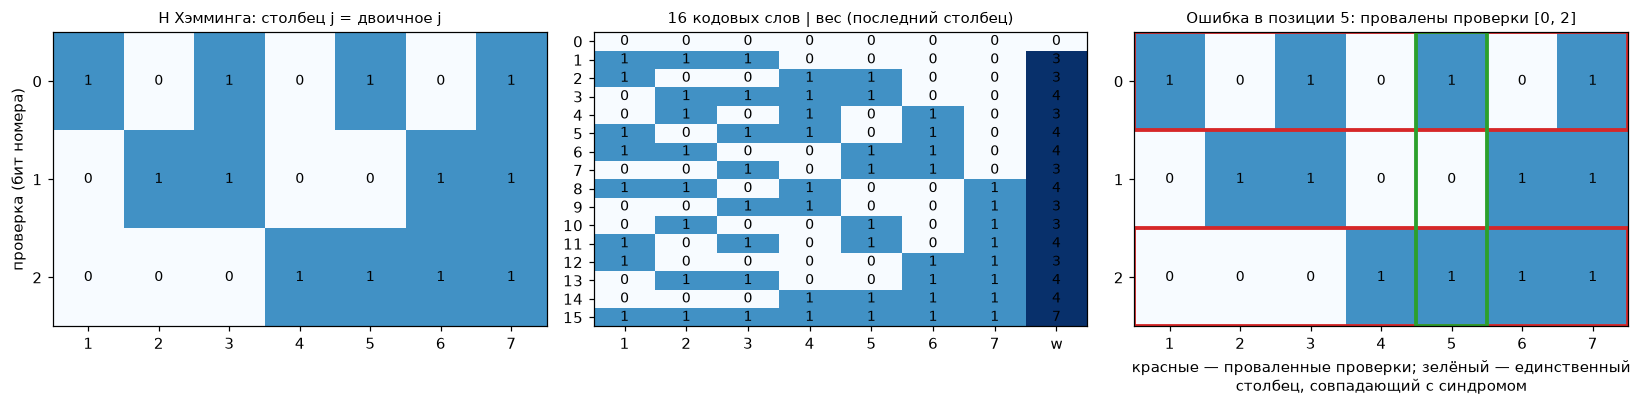

In [3]:
# Хэмминг (7,4): столбец j (j = 1..7) — двоичная запись j (строка b — бит b)
Hh = np.array([[(j >> b) & 1 for j in range(1, 8)] for b in range(3)])
words = np.array([[(w >> i) & 1 for i in range(7)] for w in range(128)])
cw = words[~((words @ Hh.T) % 2).any(1)]          # кодовые слова = нуль-пространство H над GF(2)
wt = cw.sum(1)
print(f"Слов длины 7: 128, из них кодовых (H·cᵀ = 0): {len(cw)} = 2^(7−3)")
print("Распределение весов:", {int(a): int(b) for a, b in zip(*np.unique(wt, return_counts=True))},
      "→ d_min =", wt[wt > 0].min(), "(разность двух кодовых слов — тоже кодовое слово)")

c = cw[11]; e = np.zeros(7, int); e[4] = 1        # ошибка в позиции 5 (нумерация с 1)
r = (c + e) % 2
s = (Hh @ r) % 2
pos = int(s @ (1 << np.arange(3)))
print(f"\nc = {c}\ne = {e}\nr = c⊕e = {r}")
print(f"синдром s = H·rᵀ = {s}ᵀ → двоичное {pos} → ошибка в позиции {pos}; исправлено: {np.array_equal((r + (np.arange(1, 8) == pos)) % 2, c)}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 1, 1]})
def grid(a, M, title, xt=None):
    a.imshow(M, cmap="Blues", vmin=0, vmax=1.6, aspect="auto")
    for (i, j), v in np.ndenumerate(M): a.text(j, i, int(v), ha="center", va="center", fontsize=9)
    a.set_xticks(range(M.shape[1])); a.set_xticklabels(xt if xt is not None else range(M.shape[1]))
    a.set_yticks(range(M.shape[0])); a.grid(False); a.set_title(title, fontsize=10)
grid(ax[0], Hh, "H Хэмминга: столбец j = двоичное j", range(1, 8)); ax[0].set_ylabel("проверка (бит номера)")
grid(ax[1], np.c_[cw, wt], "16 кодовых слов | вес (последний столбец)", list(range(1, 8)) + ["w"])
grid(ax[2], Hh, f"Ошибка в позиции {pos}: провалены проверки {np.nonzero(s)[0].tolist()}", range(1, 8))
for i in np.nonzero(s)[0]:
    ax[2].add_patch(plt.Rectangle((-0.5, i - 0.5), 7, 1, fill=False, ec="C3", lw=2.5))
ax[2].add_patch(plt.Rectangle((pos - 1.5, -0.5), 1, 3, fill=False, ec="C2", lw=2.5))
ax[2].set_xlabel("красные — проваленные проверки; зелёный — единственный\nстолбец, совпадающий с синдромом")
plt.tight_layout(); plt.show()

## 2. Регулярная матрица Галлагера по шагам
Нужна $H$ размера $m\times n$, $m=n\,d_v/d_c$, где **в каждой строке $d_c$ единиц, в каждом столбце $d_v$**. Конструкция Галлагера (1962):
1. **Базовая полоса** — $n/d_c$ строк «лесенкой»: строка $i$ охватывает биты $i d_c,\dots,(i+1)d_c-1$. В каждом столбце ровно одна единица.
2. Ещё $d_v-1$ полос — **случайные перестановки столбцов** базовой. Перестановка сохраняет вес строк ($d_c$) и по-прежнему даёт одну единицу на столбец.
3. Полосы ставятся друг под друга → вес столбца $d_v$.

**Ранг.** Строки каждой полосы в сумме дают вектор из одних единиц (каждый бит покрыт ровно один раз). Значит, сумма полосы 1 = сумма полосы 2 = … — это $d_v-1$ линейных зависимостей, и $\mathrm{rank}\,H\le m-(d_v-1)$. Поэтому $k=n-\mathrm{rank}H$ чуть больше $n/2$ и $R$ чуть больше $1/2$.

Ниже — по шагам для $n=24$.

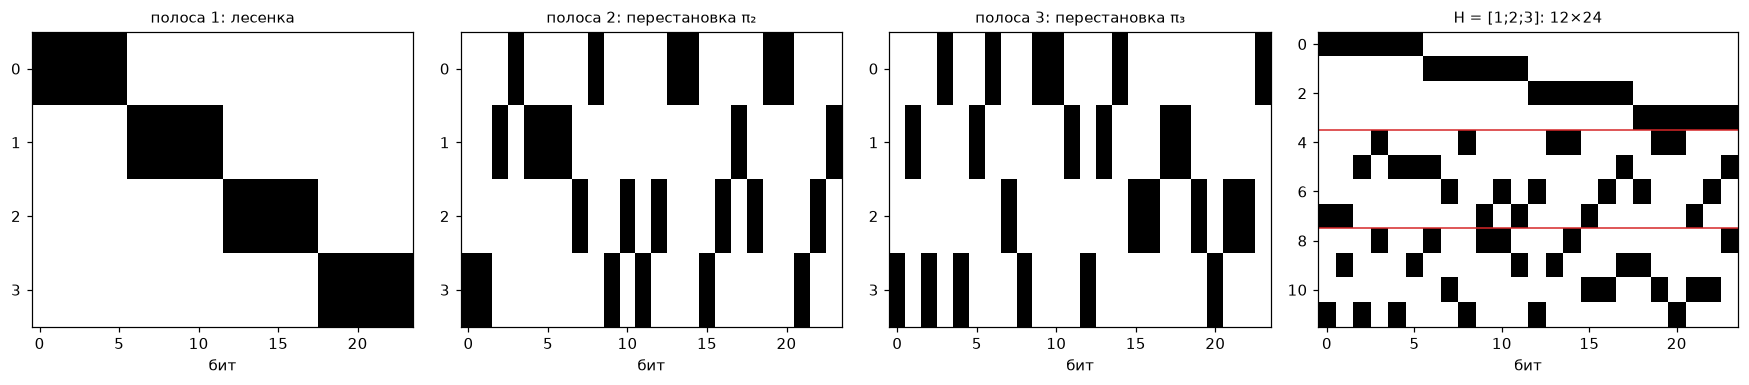

веса строк: {np.int64(6)}  веса столбцов: {np.int64(3)}
сумма строк полосы 1 (mod 2): [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
сумма строк полосы 2 (mod 2): [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
сумма строк полосы 3 (mod 2): [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
m = 12, rank H = 10 = m − (d_v − 1) → k = n − rank = 14, R = 0.583 (номинал 1 − d_v/d_c = 0.500)


In [4]:
n_s = 24; mb = n_s // DC
r2 = np.random.default_rng(5)
base = np.zeros((mb, n_s), int)
for i in range(mb):
    base[i, i * DC:(i + 1) * DC] = 1              # шаг 1: лесенка
perms = [np.arange(n_s)] + [r2.permutation(n_s) for _ in range(DV - 1)]
bands = [base[:, p] for p in perms]               # шаг 2: перестановки столбцов
Hs = np.vstack(bands)                             # шаг 3: полосы друг под другом

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.1]})
for a, M, t in zip(ax, bands + [Hs], ["полоса 1: лесенка", "полоса 2: перестановка π₂", "полоса 3: перестановка π₃",
                                      f"H = [1;2;3]: {Hs.shape[0]}×{Hs.shape[1]}"]):
    a.imshow(M, cmap="Greys", aspect="auto", interpolation="nearest"); a.set_title(t, fontsize=10); a.grid(False)
    a.set_yticks(range(0, M.shape[0], 1 if M.shape[0] <= mb else 2))
    a.set_xlabel("бит")
for b in range(1, DV): ax[3].axhline(b * mb - 0.5, color="C3", lw=1)
plt.tight_layout(); plt.show()

print("веса строк:", set(Hs.sum(1)), " веса столбцов:", set(Hs.sum(0)))
for b, M in enumerate(bands):
    print(f"сумма строк полосы {b + 1} (mod 2): {M.sum(0) % 2}")
rk = len(gf2_rref(Hs)[1])
print(f"m = {Hs.shape[0]}, rank H = {rk} = m − (d_v − 1) → k = n − rank = {n_s - rk}, R = {(n_s - rk) / n_s:.3f} (номинал 1 − d_v/d_c = {1 - DV / DC:.3f})")

## 3. Граф Таннера, циклы и обхват
Слева — игрушечный (3,6) код на 12 бит: кружки — биты, квадраты — проверки, ребро = единица в $H$. Красным выделено, кого «слышит» бит 0 за одну итерацию: 3 проверки × 5 соседей = 15 символов. В маленьком коде соседи повторяются — это **короткие циклы**: информация возвращается к биту и считается дважды, BP перестаёт быть точным. В большом коде 4-циклы выбиты конструкцией, окрестность бита на несколько итераций — почти дерево.

Справа — полная $H$ рабочего кода $n=1008$: те же три полосы, что в разделе 2. Заполнение — доли процента: на 1008 бит всего 3024 ребра, и именно число рёбер определяет сложность декодера (линейна по $n$).

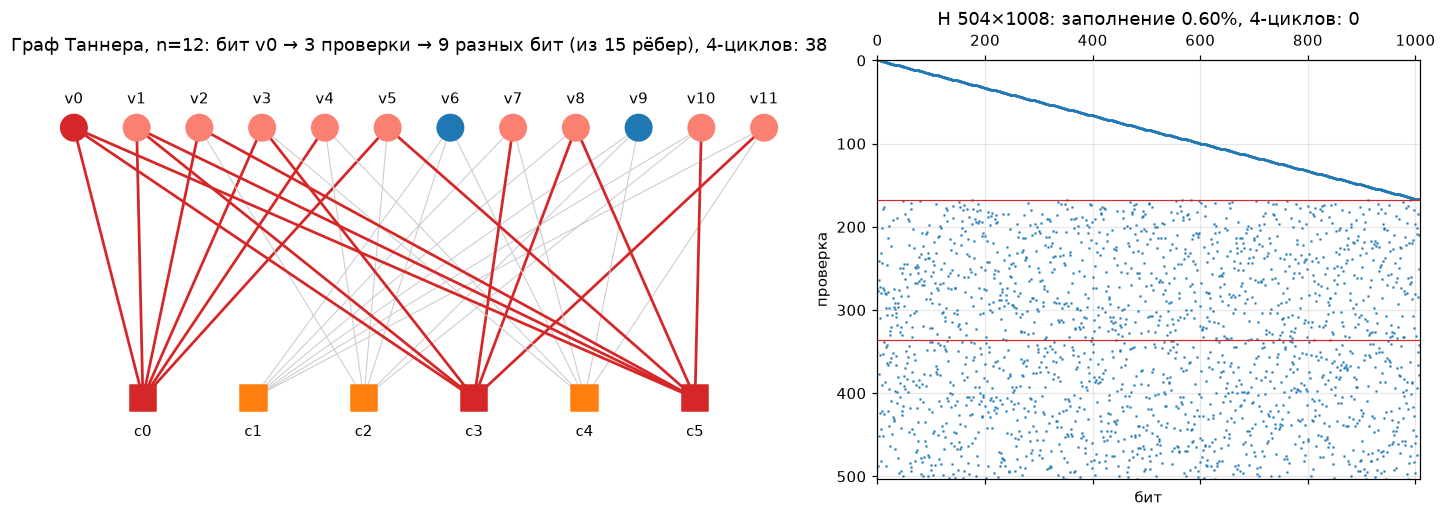

In [5]:
Ht = gallager_H(12, DV, DC, np.random.default_rng(3), fix_4cycles=False)
mt, nt = Ht.shape
xv, xc = np.linspace(0, 1, nt), np.linspace(0.1, 0.9, mt)
hot_chk = np.nonzero(Ht[:, 0])[0]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
a = ax[0]
for i, j in zip(*np.nonzero(Ht)):
    hot = i in hot_chk
    a.plot([xv[j], xc[i]], [1, 0], color="C3" if hot else "0.8", lw=1.8 if hot else 0.7, zorder=1)
heard = np.nonzero(Ht[hot_chk].any(0))[0]
a.scatter(xv, np.ones(nt), s=300, zorder=2, c=["C3" if j == 0 else ("salmon" if j in heard else "C0") for j in range(nt)])
a.scatter(xc, np.zeros(mt), s=300, marker="s", c=["C3" if i in hot_chk else "C1" for i in range(mt)], zorder=2)
for j in range(nt): a.text(xv[j], 1.09, f"v{j}", ha="center")
for i in range(mt): a.text(xc[i], -0.14, f"c{i}", ha="center")
a.set_ylim(-0.3, 1.25); a.axis("off")
a.set_title(f"Граф Таннера, n=12: бит v0 → {len(hot_chk)} проверки → {len(heard) - 1} разных бит (из 15 рёбер), 4-циклов: {count_4cycles(Ht)}")

ax[1].spy(H, markersize=0.4, aspect="auto")
for b in range(1, DV): ax[1].axhline(b * code.m / DV - 0.5, color="C3", lw=0.8)
ax[1].set_title(f"H {code.m}×{code.n}: заполнение {H.mean():.2%}, 4-циклов: {count_4cycles(H)}")
ax[1].set_xlabel("бит"); ax[1].set_ylabel("проверка")
plt.tight_layout(); plt.show()

**Почему циклы мешают.** BP точен на **дереве**: все сообщения, сходящиеся в узле, построены из непересекающихся наборов символов, значит, независимы, и их LLR можно просто складывать. Цикл длины $g$ (в рёбрах) возвращает собственную информацию бита к нему через $g/2$ итераций — она засчитывается повторно, как будто пришло новое свидетельство.

- **4-цикл** = две проверки, делящие ≥2 бита. Ищется через матрицу перекрытий $O=HH^T$: $O_{ij}$ — сколько бит общих у проверок $i$ и $j$; $O_{ij}\ge2$ → 4-цикл. `gallager_H` переставляет столбцы, пока таких пар не останется.
- **Обхват** (girth) — длина кратчайшего цикла через данный бит. Считаем обходом в ширину: ветви, вышедшие из бита разными рёбрами, где-то встретятся — сумма глубин + 1 и есть длина цикла.
- **Рост окрестности.** На дереве за $\ell$ итераций бит «слышит» $1+15+150+1500+\dots$ бит. Уже при $\ell=3$ это больше $n=1008$ → граф **обязан** замкнуться. В рабочем коде обхват 6–8, т.е. первые 3–4 итерации BP точен, дальше — приближение (как правило, хорошее: циклы длинные и разные, корреляции слабые).

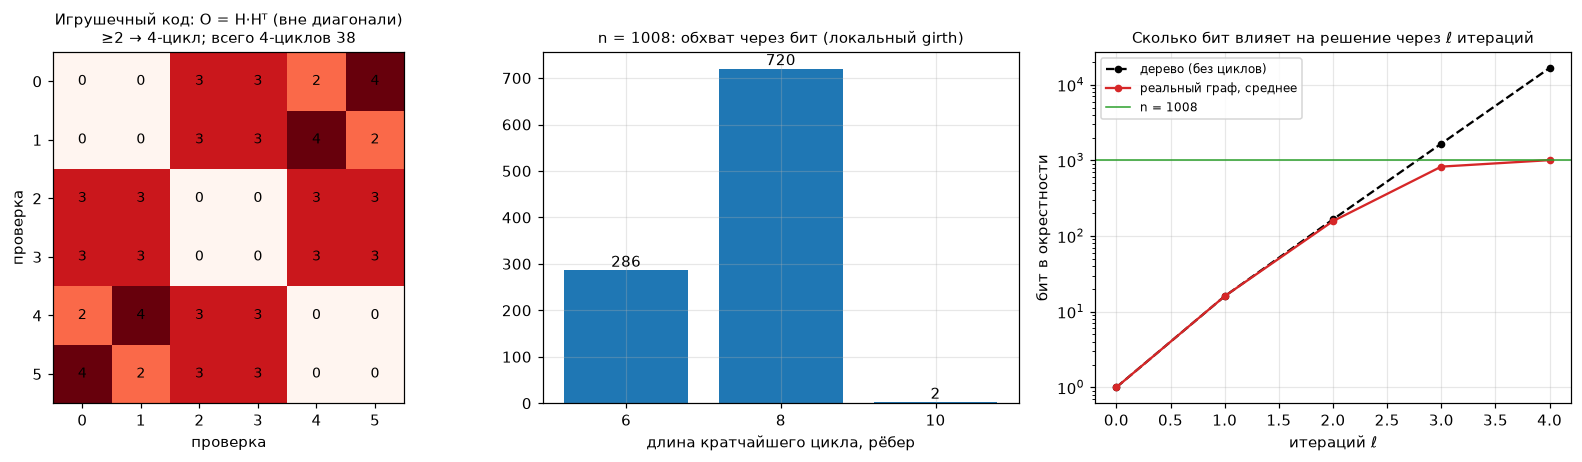

Обхват: {6: 286, 8: 720, 10: 2} → собственная информация бита возвращается через 3–4 итерации
Окрестность (среднее по битам): [   1   16  157  828 1008]  дерево: [    1    16   166  1666 16666]


In [6]:
from collections import deque
nb_v = [np.nonzero(H[:, j])[0] for j in range(code.n)]      # проверки каждого бита
nb_c = [np.nonzero(H[i])[0] for i in range(code.m)]         # биты каждой проверки

def girth_at(v0):
    # BFS по двудольному графу: узлы 0..n−1 — биты, n..n+m−1 — проверки
    dist, branch, par = {v0: 0}, {v0: -1}, {v0: None}
    q, best = deque([v0]), np.inf
    while q:
        u = q.popleft()
        if 2 * dist[u] + 1 >= best: break
        for w in (nb_v[u] + code.n if u < code.n else nb_c[u - code.n]):
            w = int(w)
            if w == par[u]: continue
            if w in dist:                         # встреча двух ветвей → цикл
                if branch[w] != branch[u]: best = min(best, dist[u] + dist[w] + 1)
            else:
                dist[w], par[w] = dist[u] + 1, u
                branch[w] = w if u == v0 else branch[u]
                q.append(w)
    return best

def growth(v0, depth=4):
    seen, front, out = {v0}, {v0}, [1]
    for _ in range(depth):
        chk = set(np.concatenate([nb_v[b] for b in front]).tolist())
        new = set(np.concatenate([nb_c[c] for c in chk]).tolist()) - seen
        seen |= new; front = new; out.append(len(seen))
    return out

g = np.array([girth_at(v) for v in range(code.n)])
gr = np.array([growth(v) for v in range(0, code.n, 8)])
tree = np.cumsum([1] + [DV * (DC - 1) * ((DV - 1) * (DC - 1)) ** l for l in range(4)])

Ot = (Ht @ Ht.T); np.fill_diagonal(Ot, 0)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
ax[0].imshow(Ot, cmap="Reds", vmin=0, vmax=4); ax[0].grid(False)
for (i, j), v in np.ndenumerate(Ot): ax[0].text(j, i, v, ha="center", va="center", fontsize=9)
ax[0].set_title(f"Игрушечный код: O = H·Hᵀ (вне диагонали)\n≥2 → 4-цикл; всего 4-циклов {count_4cycles(Ht)}", fontsize=10)
ax[0].set_xlabel("проверка"); ax[0].set_ylabel("проверка")
u_, c_ = np.unique(g, return_counts=True)
ax[1].bar([str(int(x)) for x in u_], c_, color="C0")
for x, y in zip(range(len(u_)), c_): ax[1].text(x, y, y, ha="center", va="bottom")
ax[1].set_title(f"n = {code.n}: обхват через бит (локальный girth)", fontsize=10); ax[1].set_xlabel("длина кратчайшего цикла, рёбер")
ax[2].semilogy(range(5), tree, "k--o", ms=4, label="дерево (без циклов)")
ax[2].semilogy(range(5), gr.mean(0), "C3-o", ms=4, label="реальный граф, среднее")
ax[2].axhline(code.n, color="C2", lw=1, label=f"n = {code.n}")
ax[2].set_xlabel("итераций ℓ"); ax[2].set_ylabel("бит в окрестности"); ax[2].legend(fontsize=8)
ax[2].set_title("Сколько бит влияет на решение через ℓ итераций", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Обхват: {dict(zip(u_.astype(int).tolist(), c_.tolist()))} → собственная информация бита возвращается через {int(g.min()) // 2}–{int(np.median(g)) // 2} итерации")
print("Окрестность (среднее по битам):", np.round(gr.mean(0)).astype(int), " дерево:", tree)

## 4. Кодирование над GF(2)
$H$ задаёт **проверки**, а передатчику нужен **генератор**: правило, по которому $k$ бит данных $\mathbf u$ превращаются в $\mathbf c$ с $H\mathbf c^T=0$.

**Метод Гаусса над GF(2)** (`gf2_rref`): сложение — XOR, умножение — AND, делить не нужно (единственный ненулевой элемент — 1). Идём по столбцам: находим строку с единицей в текущем столбце (**пивот**), переставляем её наверх, XOR-им её во все остальные строки с единицей в этом столбце. Получаем ступенчатую форму $A$ (те же проверки, другая запись) и разбиение столбцов:
- **столбцы-пивоты** → проверочные биты (их $\mathrm{rank}H$),
- **остальные** → информационные ($k=n-\mathrm{rank}H$).

В строке $i$ матрицы $A$ стоит одна единица среди пивотов — в столбце $p_i$. Значит, проверка $i$ читается как
$$c_{p_i}=\bigoplus_{j\in\text{info}}A_{ij}\,u_j\quad\Longrightarrow\quad \mathbf c_\text{piv}=P\,\mathbf u,\qquad P=A[:,\text{info}].$$
Это и есть систематический кодер `encode`: данные кладутся в информационные позиции как есть, проверочные биты считаются умножением на $P$.

**Цена.** $H$ разрежена, а $P$ — **плотная** (у рабочего кода ≈27% единиц против 0.6% в $H$): кодирование стоит $O(n^2)$ XOR. Поэтому в стандартах (Wi-Fi, 5G NR) проверочную часть $H$ делают двухдиагональной/квазициклической — тогда кодер линеен по $n$ и решается подстановкой без Гаусса.

**Почему дальше можно передавать хоть нули.** Код линейный, канал симметричный ($y\to-y$ при $x\to-x$), декодер симметричный — вероятность ошибки не зависит от переданного слова. Теоретический анализ (раздел 13) поэтому ведут для слова из одних нулей; в симуляции мы честно кодируем случайные данные.

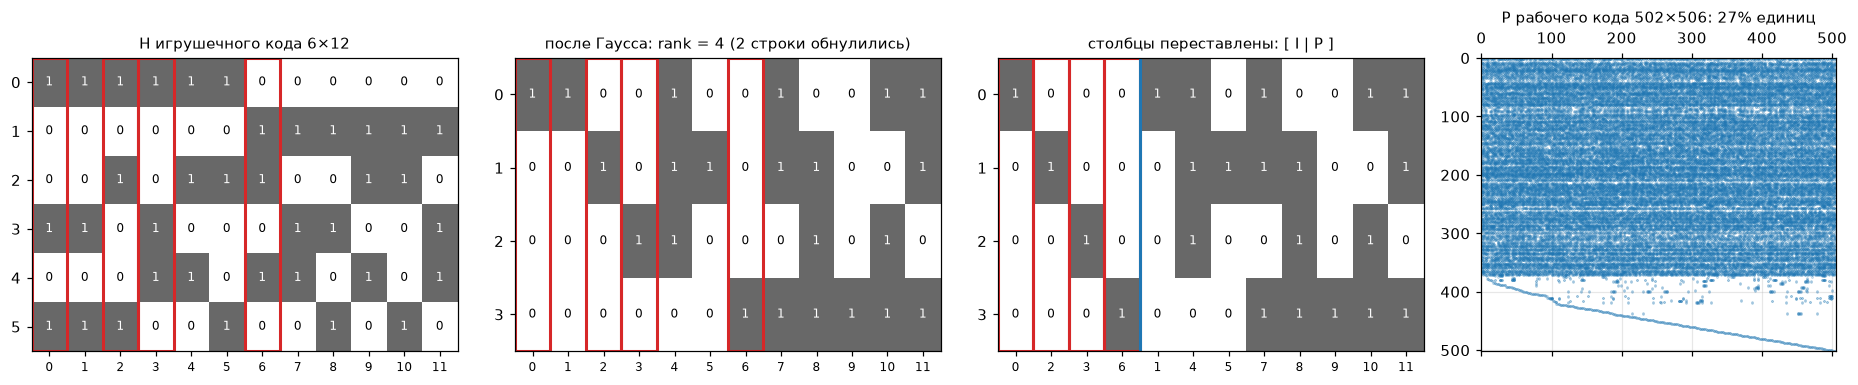

пивоты (проверочные биты): [0 2 3 6],  информационные: [ 1  4  5  7  8  9 10 11]
u = [1 0 1 1 0 0 1 0] → c = [1 1 0 1 0 1 0 1 0 0 1 0]  (c[info] = [1 0 1 1 0 0 1 0] = u)
H·cᵀ = [0 0 0 0 0 0]

Рабочий код: кодирование ≈ 68926 XOR (плотная P) против 3024 рёбер в одной итерации декодера
Кодер: H·cᵀ = 0 для случайных слов — True


In [7]:
toy = LDPC(Ht)
A_t, piv_t, info_t = toy.A, toy.piv, toy.info
order = np.r_[piv_t, info_t]                      # переставим столбцы: [пивоты | данные] → A = [I | P]
u_t = np.array([[1, 0, 1, 1, 0, 0, 1, 0]])[:, :toy.k]
c_t = toy.encode(u_t)

fig, ax = plt.subplots(1, 4, figsize=(17, 3.6), gridspec_kw={"width_ratios": [1.2, 1.2, 1.2, 1]})
def bits(a, M, title, xt, hl=()):
    a.imshow(M, cmap="Greys", vmin=0, vmax=1.5, aspect="auto"); a.grid(False)
    for (i, j), v in np.ndenumerate(M): a.text(j, i, int(v), ha="center", va="center", fontsize=8, color="w" if v else "k")
    a.set_xticks(range(M.shape[1])); a.set_xticklabels(xt, fontsize=8); a.set_yticks(range(M.shape[0])); a.set_title(title, fontsize=10)
    for j in hl: a.add_patch(plt.Rectangle((j - 0.5, -0.5), 1, M.shape[0], fill=False, ec="C3", lw=2))
bits(ax[0], Ht, f"H игрушечного кода {Ht.shape[0]}×{Ht.shape[1]}", range(toy.n), piv_t)
bits(ax[1], A_t, f"после Гаусса: rank = {len(piv_t)} (2 строки обнулились)", range(toy.n), piv_t)
bits(ax[2], A_t[:, order], "столбцы переставлены: [ I | P ]", order, range(len(piv_t)))
ax[2].axvline(len(piv_t) - 0.5, color="C0", lw=2)
ax[3].spy(code.P, markersize=0.05, aspect="auto"); ax[3].set_title(f"P рабочего кода {code.P.shape[0]}×{code.P.shape[1]}: {code.P.mean():.0%} единиц", fontsize=10)
plt.tight_layout(); plt.show()

print(f"пивоты (проверочные биты): {piv_t},  информационные: {info_t}")
print(f"u = {u_t[0]} → c = {c_t[0]}  (c[info] = {c_t[0, info_t]} = u)")
print(f"H·cᵀ = {(Ht @ c_t[0]) % 2}")
print(f"\nРабочий код: кодирование ≈ {int(code.P.sum())} XOR (плотная P) против {code.E} рёбер в одной итерации декодера")
U = rng.integers(0, 2, (5, code.k))
print("Кодер: H·cᵀ = 0 для случайных слов —", code.syndrome_ok(code.encode(U)).all())

## 5. Канал → LLR
**Откуда $2y/\sigma^2$.** По формуле Байеса при равновероятных битах
$$L=\ln\frac{p(y\,|\,x=+1)}{p(y\,|\,x=-1)}=\ln\frac{e^{-(y-1)^2/2\sigma^2}}{e^{-(y+1)^2/2\sigma^2}}=\frac{(y+1)^2-(y-1)^2}{2\sigma^2}=\frac{2y}{\sigma^2}.$$
Обратно: $P(c=1\,|\,L)=\dfrac1{1+e^{L}}$, $P(c=0\,|\,L)=\dfrac1{1+e^{-L}}$. $|L|=2$ — ошибка с вероятностью 12%, $|L|=5$ — 0.7%, $|L|=10$ — $5\cdot10^{-5}$. LLR удобны тем, что независимые свидетельства **складываются** (произведение правдоподобий → сумма логарифмов), а знаменатель $p(y)$ сокращается.

**Почему $\mathcal N(\mu,2\mu)$.** При $x=+1$: $y\sim\mathcal N(1,\sigma^2)$ → $L=2y/\sigma^2\sim\mathcal N\big(2/\sigma^2,\;4/\sigma^2\big)$ — дисперсия ровно вдвое больше среднего. Это свойство («симметрия» / consistency) сохраняется при сложении LLR в узлах-битах — на нём держится гауссово приближение раздела 11.

При $E_b/N_0$ = `EBN0_DB` на символ приходится $E_s/N_0=R\,E_b/N_0$ — заметно меньше 0 дБ. Жёсткое решение по знаку ошибается в каждом ~8-м символе. Справа — LLR, домноженный на передаваемый знак: правильные решения справа от нуля, ошибки слева. Гауссиана $\mathcal N(\mu,2\mu)$ — теория. Справа — как LLR превращается в вероятность ошибки.

Главное число — **сколько информации о бите несёт один символ** $I=J(\sqrt{8RE_b/N_0})$. Если $I>R$, код в принципе может всё исправить (Шеннон); если $I<R$ — никакой декодер не поможет.

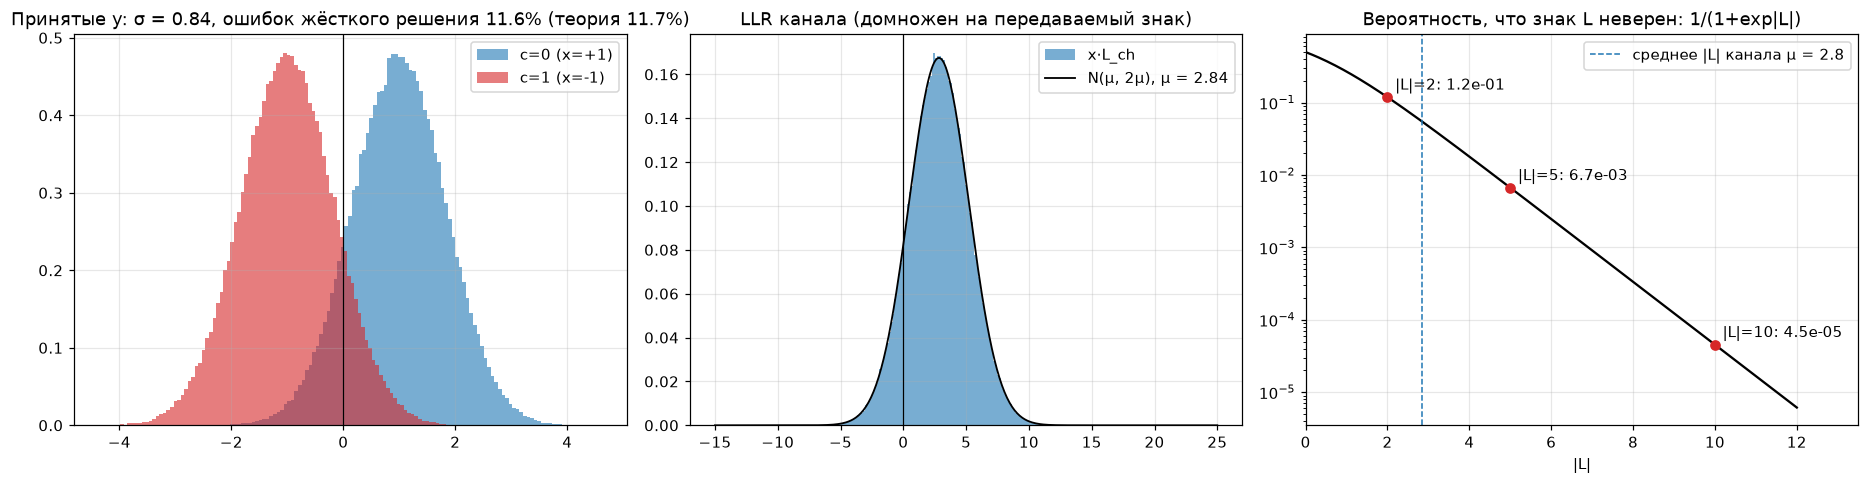

Информация на символ: измерено 0.604 бит, теория J(σ_ch) = 0.604 бит, нужно R = 0.502 бит → запас есть


In [8]:
U = rng.integers(0, 2, (400, code.k))
C = code.encode(U); X = 1 - 2.0 * C
y, L, sigma = channel(C, EBN0_DB, code.R, rng)
mu = 2 / sigma**2

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for c, col in [(0, "C0"), (1, "C3")]:
    ax[0].hist(y[C == c], 120, density=True, alpha=0.6, color=col, label=f"c={c} (x={1-2*c:+d})")
ax[0].axvline(0, color="k", lw=0.8); ax[0].legend()
ax[0].set_title(f"Принятые y: σ = {sigma:.2f}, ошибок жёсткого решения {np.mean((y < 0) != C):.1%} "
                f"(теория {0.5*erfc(np.sqrt(code.R*10**(EBN0_DB/10))):.1%})")
l = np.linspace(-15, 25, 400)
ax[1].hist((L * X).ravel(), 150, density=True, alpha=0.6, label="x·L_ch")
ax[1].plot(l, np.exp(-(l - mu)**2 / (4 * mu)) / np.sqrt(4 * np.pi * mu), "k", lw=1.2, label=f"N(μ, 2μ), μ = {mu:.2f}")
ax[1].axvline(0, color="k", lw=0.8); ax[1].legend()
ax[1].set_title("LLR канала (домножен на передаваемый знак)")
ll = np.linspace(0, 12, 300)
ax[2].semilogy(ll, 1 / (1 + np.exp(ll)), "k")
for v in [2, 5, 10]:
    ax[2].plot(v, 1 / (1 + np.exp(v)), "C3o"); ax[2].annotate(f"|L|={v}: {1 / (1 + np.exp(v)):.1e}", (v, 1 / (1 + np.exp(v))), xytext=(5, 5), textcoords="offset points")
ax[2].axvline(mu, color="C0", ls="--", lw=1, label=f"среднее |L| канала μ = {mu:.1f}"); ax[2].legend()
ax[2].set_xlim(0, 13.5); ax[2].set_xlabel("|L|"); ax[2].set_title("Вероятность, что знак L неверен: 1/(1+exp|L|)")
plt.tight_layout(); plt.show()

print(f"Информация на символ: измерено {mi(L, X):.3f} бит, теория J(σ_ch) = {J(sch(EBN0_DB, code.R)):.3f} бит, "
      f"нужно R = {code.R:.3f} бит → запас {'есть' if J(sch(EBN0_DB, code.R)) > code.R else 'НЕТ'}")

## 6. Узел-проверка: операция ⊞, tanh-правило и min-sum
Проверка говорит: $v_1\oplus v_2\oplus\dots\oplus v_{d_c}=0$, т.е. каждый бит равен XOR остальных. Что проверка знает о бите $v$, если знает LLR остальных?

**Два бита.** Пусть $p_i=P(v_i=0)$, $q_i=1-p_i$. Тогда $P(v_1\oplus v_2=0)=p_1p_2+q_1q_2$, и
$$P(v_1\oplus v_2=0)-P(v_1\oplus v_2=1)=(p_1-q_1)(p_2-q_2).$$
Разность вероятностей через LLR: $p-q=\dfrac{e^{L/2}-e^{-L/2}}{e^{L/2}+e^{-L/2}}=\tanh\dfrac L2$. Получаем
$$\tanh\frac{L_1\boxplus L_2}{2}=\tanh\frac{L_1}{2}\tanh\frac{L_2}{2},\qquad\text{и по индукции}\qquad \tanh\frac{L_{c\to v}}{2}=\prod_{v'\ne v}\tanh\frac{L_{v'\to c}}{2}.$$

**Свойства ⊞** (видно на рисунке):
- знак результата — произведение знаков (это просто XOR жёстких решений);
- $|L_1\boxplus L_2|\le\min(|L_1|,|L_2|)$ — **слабое звено**: если про один бит ничего не известно ($L=0$), то и про XOR ничего; поэтому важно, чтобы $d_c$ было небольшим;
- **min-sum**: $L_1\boxplus L_2\approx\operatorname{sign}L_1\operatorname{sign}L_2\cdot\min(|L_1|,|L_2|)$ — точно, когда один вход много слабее остальных, и **завышает** уверенность, когда входы сравнимы. Множитель $\alpha<1$ компенсирует завышение в среднем. Справа — оценка лучшего $\alpha$ прямо по данным: МНК-наклон «точное ⊞ против min-sum» на 5 входах из канала.

Ниже tanh-правило проверено полным перебором $2^5$ комбинаций бит.

входные LLR: [ 2.1 -3.4  0.9  4.2  1.6]
перебор 32 комбинаций: P(XOR = 1) = 0.59941 → LLR = ln(P0/P1) = -0.40302
tanh-правило:  ⊞ = -0.40302
min-sum:       -0.90000  (слабейший вход +0.90)


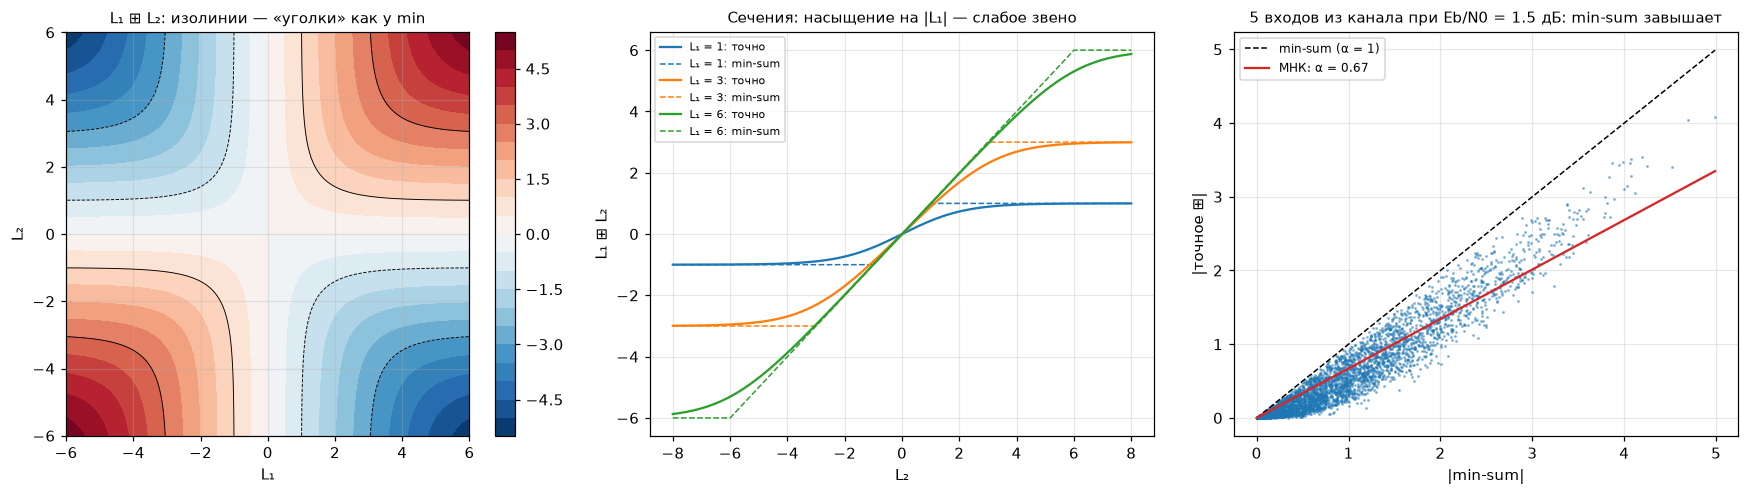

Оценка нормировки по каналу: α ≈ 0.67 (в декодере ALPHA_MS = 0.8; на поздних итерациях входы больше и α ближе к 1)


In [9]:
Lin = np.array([2.1, -3.4, 0.9, 4.2, 1.6])[:DC - 1]   # пять входов: один слабый, один отрицательный
p1 = 1 / (1 + np.exp(Lin))                        # P(бит = 1)
combos = np.array([[(w >> i) & 1 for i in range(DC - 1)] for w in range(2 ** (DC - 1))])
Pc = np.prod(np.where(combos, p1, 1 - p1), 1)
p_x1 = Pc[combos.sum(1) % 2 == 1].sum()
print(f"входные LLR: {np.round(Lin, 2)}")
print(f"перебор {2 ** (DC - 1)} комбинаций: P(XOR = 1) = {p_x1:.5f} → LLR = ln(P0/P1) = {np.log((1 - p_x1) / p_x1):+.5f}")
print(f"tanh-правило:  ⊞ = {boxplus(*Lin):+.5f}")
print(f"min-sum:       {np.prod(np.sign(Lin)) * np.abs(Lin).min():+.5f}  (слабейший вход {Lin[np.abs(Lin).argmin()]:+.2f})")

l1 = np.linspace(-6, 6, 241)
G1, G2 = np.meshgrid(l1, l1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
cs = ax[0].contourf(G1, G2, boxplus(G1, G2), 21, cmap="RdBu_r"); plt.colorbar(cs, ax=ax[0])
ax[0].contour(G1, G2, boxplus(G1, G2), [-3, -1, 1, 3], colors="k", linewidths=0.6)
ax[0].set_xlabel("L₁"); ax[0].set_ylabel("L₂"); ax[0].set_title("L₁ ⊞ L₂: изолинии — «уголки» как у min", fontsize=10); ax[0].set_aspect("equal")
lx = np.linspace(-8, 8, 400)
for a1, col in [(1, "C0"), (3, "C1"), (6, "C2")]:
    ax[1].plot(lx, boxplus(a1, lx), col, label=f"L₁ = {a1}: точно")
    ax[1].plot(lx, np.sign(lx) * np.minimum(a1, np.abs(lx)), col, ls="--", lw=1, label=f"L₁ = {a1}: min-sum")
ax[1].set_xlabel("L₂"); ax[1].set_ylabel("L₁ ⊞ L₂"); ax[1].legend(fontsize=7); ax[1].set_title("Сечения: насыщение на |L₁| — слабое звено", fontsize=10)

_, Lsmp, _ = channel(np.zeros((4000, DC - 1), np.uint8), EBN0_DB, code.R, rng)    # 5 входов из канала
ex = np.abs(boxplus(*Lsmp.T)); ms = np.abs(Lsmp).min(1)
a_fit = np.sum(ex * ms) / np.sum(ms ** 2)
ax[2].plot(ms, ex, ".", ms=2, alpha=0.4)
mm = np.linspace(0, ms.max(), 2)
ax[2].plot(mm, mm, "k--", lw=1, label="min-sum (α = 1)"); ax[2].plot(mm, a_fit * mm, "C3", lw=1.5, label=f"МНК: α = {a_fit:.2f}")
ax[2].set_xlabel("|min-sum|"); ax[2].set_ylabel("|точное ⊞|"); ax[2].legend(fontsize=8)
ax[2].set_title(f"{DC - 1} входов из канала при Eb/N0 = {EBN0_DB} дБ: min-sum завышает", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Оценка нормировки по каналу: α ≈ {a_fit:.2f} (в декодере ALPHA_MS = {ALPHA_MS}; на поздних итерациях входы больше и α ближе к 1)")

## 7. Узел-бит: сложение свидетельств и принцип экстринсика
Бит $v$ получает $d_v$ сообщений от своих проверок плюс канальный LLR. Если они независимы, правдоподобия перемножаются, а LLR **складываются**:
$$L_v^\text{апост}=L_\text{ch}+\sum_{c\in N(v)}L_{c\to v}.$$
Знак $L_v^\text{апост}$ — текущее решение, по нему проверяется синдром для раннего останова.

**Экстринсик.** Проверке $c$ бит отправляет сумму **без** её собственного вклада:
$$L_{v\to c}=L_v^\text{апост}-L_{c\to v}.$$
Если этого не сделать, проверка на следующей итерации получит назад своё же мнение, примет его за независимое подтверждение и усилит — положительная обратная связь. Уверенность растёт экспоненциально, а ошибки остаются: декодер «убеждает сам себя». То же самое правило «не возвращай отправителю его сообщение» действует и в узле-проверке (`loo_prod` — произведение по всем входам, *кроме* своего).

Эксперимент: рабочий код, тот же шум, декодер с экстринсиком и с «эхом».

экстринсик (правильно)    : BER = 1.58e-02, FER = 0.27


эхо: L_v→c = L_апост      : BER = 8.22e-02, FER = 0.97


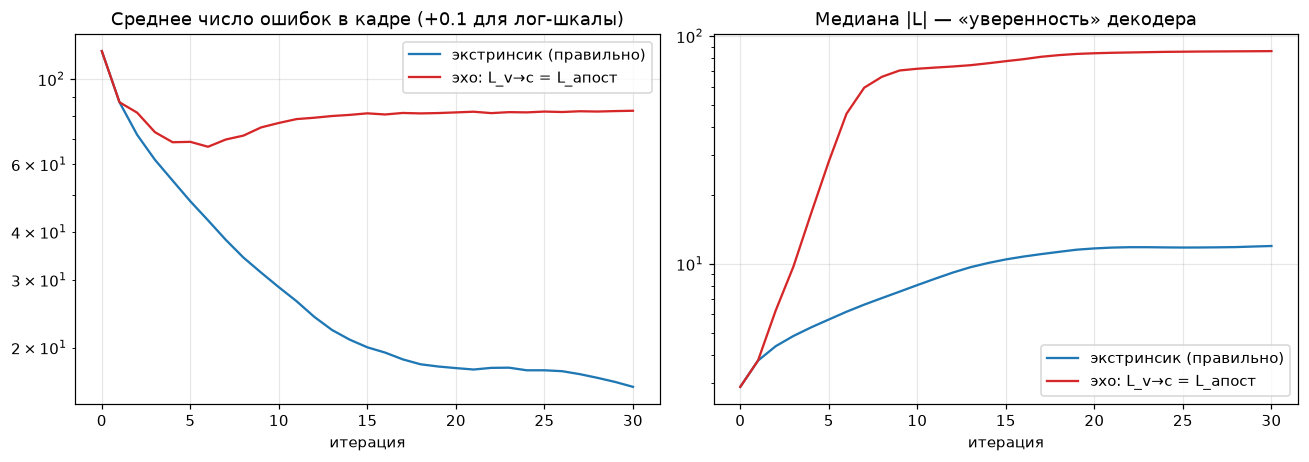

In [10]:
F7 = 200
U = rng.integers(0, 2, (F7, code.k)); C = code.encode(U); X = 1 - 2.0 * C
_, L7, _ = channel(C, EBN0_DB, code.R, rng)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for ext, col, name in [(True, "C0", "экстринсик (правильно)"), (False, "C3", "эхо: L_v→c = L_апост")]:
    tr = []
    Ch, nit = code.decode(L7, 30, "spa", cb=lambda it, Lv, Lcv: tr.append(((Lv * X < 0).sum(1).mean(), np.median(np.abs(Lv)))), extrinsic=ext)
    tr = np.array(tr)
    ax[0].semilogy(tr[:, 0] + 0.1, col, label=name); ax[1].semilogy(tr[:, 1], col, label=name)
    print(f"{name:26s}: BER = {np.mean(Ch[:, code.info] != U):.2e}, FER = {1 - code.syndrome_ok(Ch).mean():.2f}")
ax[0].set_title("Среднее число ошибок в кадре (+0.1 для лог-шкалы)"); ax[1].set_title("Медиана |L| — «уверенность» декодера")
for a in ax: a.set_xlabel("итерация"); a.legend()
plt.tight_layout(); plt.show()

## 8. BP вручную на 12-битном коде
Возьмём игрушечный код из раздела 3 ($n=12$, $k=8$), передадим случайное кодовое слово и подберём реализацию шума, где канал дал **две ошибки** и BP исправляет их не с первой итерации. Распечатаем первую итерацию для ошибочного бита полностью, затем посмотрим, как сообщения меняются по итерациям.

На рисунках цвет — LLR, **домноженный на передаваемый знак** $x$: синий — «верно и уверенно», красный — «неверно». Квадраты-проверки зелёные, если текущее жёсткое решение их удовлетворяет. Толщина ребра — $|L_{c\to v}|$, цвет ребра — помогает сообщение биту (синий) или тянет к ошибке (красный).

Обратите внимание: в 12-битном коде много 4-циклов (раздел 3), поэтому сообщения быстро становятся коррелированными — и всё же две ошибки исправляются.

In [11]:
for seed in range(1000):                          # ищем шум: 2 ошибки в канале, BP исправляет за ≥3 итерации
    rs = np.random.default_rng(seed)
    u8 = rs.integers(0, 2, (1, toy.k)); c8 = toy.encode(u8); x8 = 1 - 2.0 * c8[0]
    _, L8, _ = channel(c8, 3.0, toy.R, rs)
    if ((L8[0] < 0) != c8[0]).sum() == 2:
        Ch8, nit8 = toy.decode(L8, 20, "spa")
        if (Ch8 == c8).all() and nit8[0] >= 3: break
Lch8 = L8[0]
err8 = np.nonzero((Lch8 < 0) != c8[0])[0]
print(f"seed = {seed}: c = {c8[0]}, ошибки канала в битах {err8}, BP сошёлся за {nit8[0]} итерации")
print("x·L_ch =", np.round(Lch8 * x8, 2))

# ── развёрнутая первая итерация для первого ошибочного бита ──
v = err8[0]
print(f"\nИтерация 1, бит v{v}: L_ch = {Lch8[v]:+.2f} (передан x = {x8[v]:+.0f} → знак неверный)")
tot = Lch8[v]
for cc in np.nonzero(Ht[:, v])[0]:
    others = [int(j) for j in np.nonzero(Ht[cc])[0] if j != v]
    Lin_ = Lch8[others]                           # на итерации 1 бит шлёт проверке свой L_ch (L_c→v ещё 0)
    t = np.tanh(Lin_ / 2)
    out = 2 * np.arctanh(np.prod(t))
    ms_ = ALPHA_MS * np.prod(np.sign(Lin_)) * np.abs(Lin_).min()
    print(f"  c{cc}: входы от v{others} = {np.round(Lin_, 2)}")
    print(f"       tanh(L/2) = {np.round(t, 3)}, произведение = {np.prod(t):+.4f} → L_c{cc}→v{v} = {out:+.2f}   (min-sum·α: {ms_:+.2f})")
    tot += out
print(f"  апостериорный L_v{v} = L_ch + Σ = {tot:+.2f} → знак {'исправлен' if tot * x8[v] > 0 else 'ещё неверный'}")

tr8 = []
toy.decode(L8, 20, "spa", cb=lambda it, Lv, Lcv: tr8.append((Lv[0].copy(), Lcv[0].copy())))
print(f"  проверка по декодеру: L_v{v} после итерации 1 = {tr8[1][0][v]:+.2f}")

seed = 302: c = [1 1 0 0 1 1 0 1 0 1 1 1], ошибки канала в битах [1 4], BP сошёлся за 4 итерации
x·L_ch = [ 6.75 -0.34  9.92  7.29 -2.43  0.3   6.86 12.13  2.23  5.04  9.29  2.  ]

Итерация 1, бит v1: L_ch = +0.34 (передан x = -1 → знак неверный)
  c0: входы от v[0, 2, 3, 4, 5] = [-6.75  9.92  7.29  2.43 -0.3 ]
       tanh(L/2) = [-0.998  1.     0.999  0.838 -0.148], произведение = +0.1237 → L_c0→v1 = +0.25   (min-sum·α: +0.24)
  c3: входы от v[0, 3, 7, 8, 11] = [ -6.75   7.29 -12.13   2.23  -2.  ]
       tanh(L/2) = [-0.998  0.999 -1.     0.806 -0.761], произведение = -0.6109 → L_c3→v1 = -1.42   (min-sum·α: -1.60)
  c5: входы от v[0, 2, 5, 8, 10] = [-6.75  9.92 -0.3   2.23 -9.29]
       tanh(L/2) = [-0.998  1.    -0.148  0.806 -1.   ], произведение = -0.1190 → L_c5→v1 = -0.24   (min-sum·α: -0.24)
  апостериорный L_v1 = L_ch + Σ = -1.07 → знак исправлен
  проверка по декодеру: L_v1 после итерации 1 = -1.07


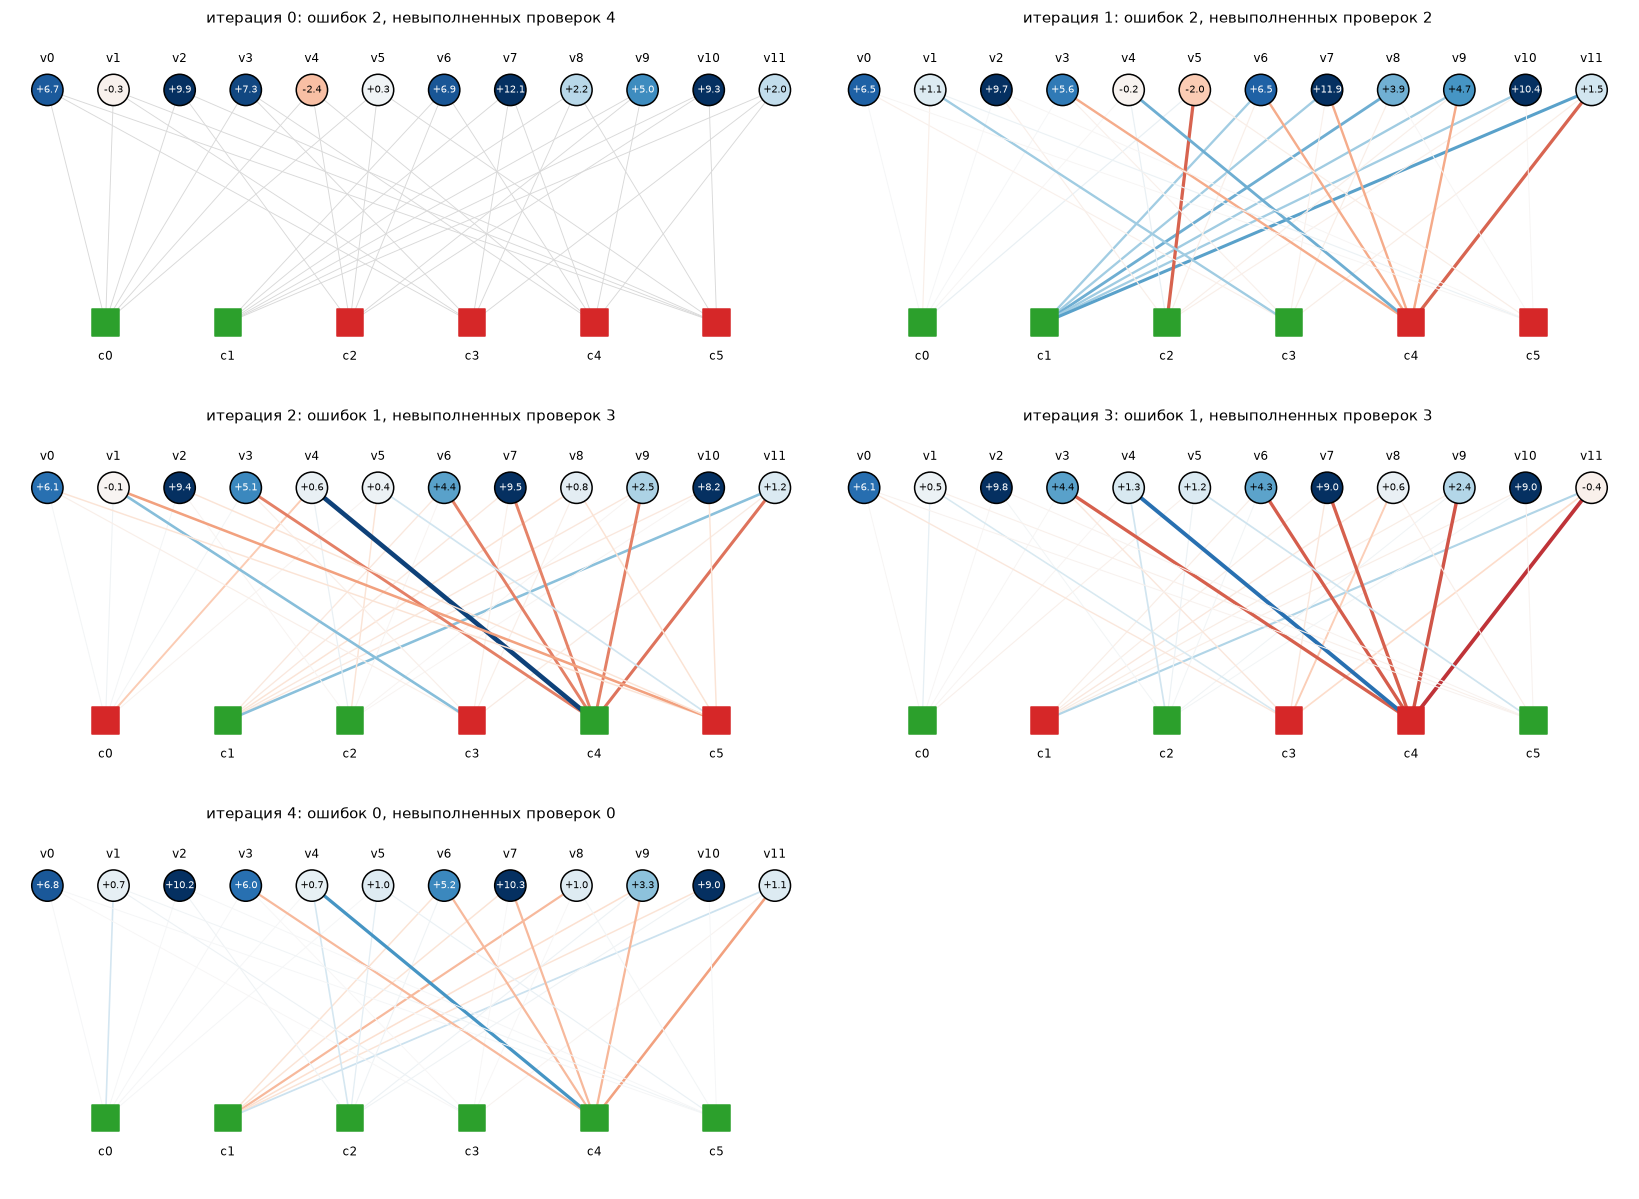

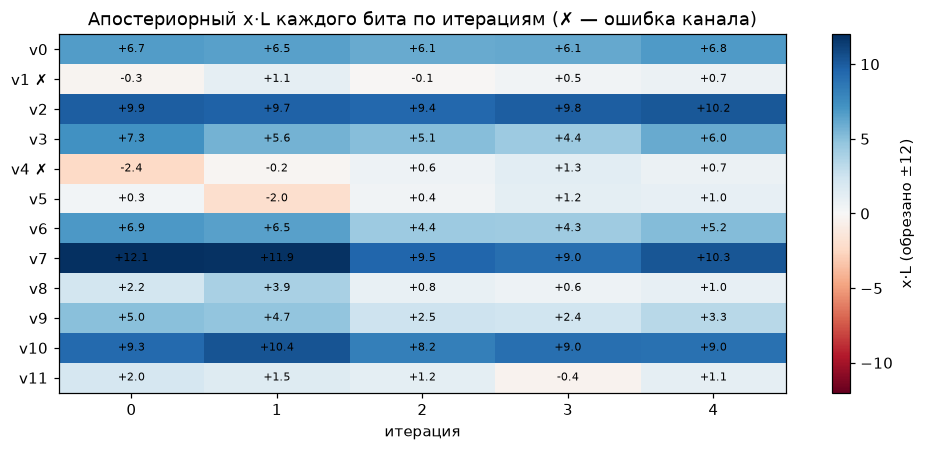

In [12]:
def draw_tanner(a, Hm, xL, xLcv, title, vmax=8, emax=4):
    m_, n_ = Hm.shape
    xv_, xc_ = np.linspace(0, 1, n_), np.linspace(0.08, 0.92, m_)
    cm = plt.cm.RdBu
    rr, cc_ = np.nonzero(Hm)                      # рёбра в том же порядке, что в LDPC (по проверкам)
    for e, (i, j) in enumerate(zip(rr, cc_)):
        w = xLcv[e]
        a.plot([xv_[j], xc_[i]], [1, 0], color=cm(0.5 + np.clip(w, -emax, emax) / (2 * emax)) if w != 0 else "0.85",
               lw=0.6 + 2.6 * min(abs(w), emax) / emax, zorder=1)
    a.scatter(xv_, np.ones(n_), s=420, c=np.clip(xL, -vmax, vmax), cmap=cm, vmin=-vmax, vmax=vmax, edgecolors="k", zorder=2)
    for j in range(n_): a.text(xv_[j], 1, f"{xL[j]:+.1f}", ha="center", va="center", fontsize=6.5, zorder=3,
                                   color="w" if abs(xL[j]) > 0.6 * vmax else "k")
    hard = (xL < 0).astype(int)                   # ошибки = биты с неверным знаком; синдром ошибок = синдром решения
    sat = (Hm @ hard) % 2 == 0
    a.scatter(xc_, np.zeros(m_), s=300, marker="s", c=["C2" if s_ else "C3" for s_ in sat], zorder=2)
    for j in range(n_): a.text(xv_[j], 1.12, f"v{j}", ha="center", fontsize=8)
    for i in range(m_): a.text(xc_[i], -0.16, f"c{i}", ha="center", fontsize=8)
    a.set_ylim(-0.3, 1.25); a.axis("off"); a.set_title(title, fontsize=10)

xe8 = x8[toy.ev]
snaps = list(range(min(len(tr8), 6)))
fig, ax = plt.subplots(3, 2, figsize=(15, 11))
for a in ax.ravel()[len(snaps):]: a.axis("off")
for a, it in zip(ax.ravel(), snaps):
    xL, Lc = tr8[it][0] * x8, tr8[it][1] * xe8
    draw_tanner(a, Ht, xL, Lc, f"итерация {it}: ошибок {(xL < 0).sum()}, невыполненных проверок {((Ht @ (xL < 0)) % 2).sum()}")
plt.tight_layout(); plt.show()

M8 = np.array([t[0] * x8 for t in tr8]).T
fig, a = plt.subplots(figsize=(1.2 * len(tr8) + 3, 4.2))
im = a.imshow(np.clip(M8, -12, 12), cmap="RdBu", vmin=-12, vmax=12, aspect="auto"); plt.colorbar(im, ax=a, label="x·L (обрезано ±12)")
for (j, it), val in np.ndenumerate(M8): a.text(it, j, f"{val:+.1f}", ha="center", va="center", fontsize=7)
a.set_yticks(range(toy.n)); a.set_yticklabels([f"v{j}" + (" ✗" if j in err8 else "") for j in range(toy.n)])
a.set_xticks(range(len(tr8))); a.set_xlabel("итерация"); a.grid(False)
a.set_title("Апостериорный x·L каждого бита по итерациям (✗ — ошибка канала)")
plt.tight_layout(); plt.show()

## 9. Векторный декодер: как устроен класс `LDPC`
Писать BP циклами по узлам — медленно. В `LDPC` всё сводится к операциям над **массивом рёбер** длины $E=n d_v=m d_c$:

- `np.nonzero(H)` перечисляет единицы $H$ построчно → рёбра **упорядочены по проверкам**: рёбра проверки $i$ — это $i d_c,\dots,(i+1)d_c-1$. Поэтому `Lvc.reshape(F, m, dc)` сразу даёт для каждой проверки её $d_c$ входов, а `check_update` работает по последней оси.
- `ev[e]` — бит на конце ребра $e$: `La[:, ev]` раздаёт апостериорный LLR бита на все его рёбра.
- `var` (размер $n\times d_v$) — номера рёбер каждого бита (`argsort` по `ev`): `Lcv[:, var].sum(-1)` собирает сообщения проверок к биту.
- `loo_prod` — «произведение всех, кроме себя» через префиксные и суффиксные произведения: $O(d_c)$ вместо $O(d_c^2)$ и без деления на $\tanh\approx0$.
- min-sum: для выхода нужен минимум **остальных** входов — это первый минимум для всех, кроме самого минимального входа, которому достаётся второй минимум.
- `layers` — разбиение проверок на слои без общих бит (для layered-расписания, раздел 14). У Галлагера слои совпадают с полосами.

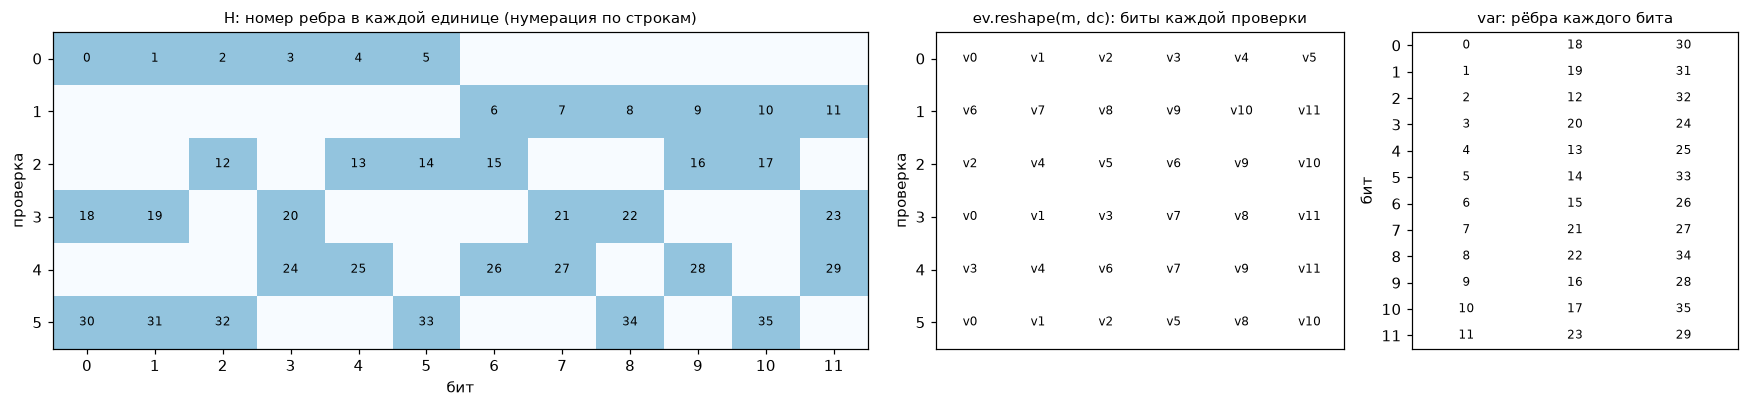

loo_prod совпадает с наивным «произведением без себя»: True
check_update('spa') = ⊞ остальных входов: True
min-sum на примере: входы [ 2.47 -2.02 -3.86  3.23  1.08 -2.71] → выходы [-1.08  1.08  1.08 -1.08 -2.02  1.08]
слои рабочего кода: 3 по 168 проверок; в каждом слое каждый бит ровно один раз — True


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw={"width_ratios": [2, 1, 0.8]})
Eidx = -np.ones(Ht.shape, int); Eidx[toy.ec, toy.ev] = np.arange(toy.E)
ax[0].imshow(Ht, cmap="Blues", vmin=0, vmax=2.5, aspect="auto"); ax[0].grid(False)
for (i, j), e in np.ndenumerate(Eidx):
    if e >= 0: ax[0].text(j, i, e, ha="center", va="center", fontsize=8)
ax[0].set_title("H: номер ребра в каждой единице (нумерация по строкам)", fontsize=10); ax[0].set_xlabel("бит"); ax[0].set_ylabel("проверка")
ax[0].set_xticks(range(toy.n)); ax[0].set_yticks(range(toy.m))
EV = toy.ev.reshape(toy.m, toy.dc)
ax[1].imshow(np.zeros_like(EV), cmap="Greys", vmin=0, vmax=1, aspect="auto"); ax[1].grid(False)
for (i, j), b in np.ndenumerate(EV): ax[1].text(j, i, f"v{b}", ha="center", va="center", fontsize=8)
ax[1].set_title("ev.reshape(m, dc): биты каждой проверки", fontsize=10); ax[1].set_ylabel("проверка"); ax[1].set_xticks([])
ax[2].imshow(np.zeros_like(toy.var), cmap="Greys", vmin=0, vmax=1, aspect="auto"); ax[2].grid(False)
for (j, k), e in np.ndenumerate(toy.var): ax[2].text(k, j, e, ha="center", va="center", fontsize=8)
ax[2].set_title("var: рёбра каждого бита", fontsize=10); ax[2].set_ylabel("бит"); ax[2].set_xticks([]); ax[2].set_yticks(range(toy.n))
plt.tight_layout(); plt.show()

t = np.tanh(rng.normal(0, 2, (4, DC)) / 2)
naive = np.array([[np.prod(np.delete(row, i)) for i in range(DC)] for row in t])
print("loo_prod совпадает с наивным «произведением без себя»:", np.allclose(loo_prod(t), naive))
Lt = rng.normal(0, 3, (3, DC))
naive_bp = np.array([[boxplus(*np.delete(row, i)) for i in range(DC)] for row in Lt])
print("check_update('spa') = ⊞ остальных входов:", np.allclose(check_update(Lt, "spa"), naive_bp))
print("min-sum на примере: входы", np.round(Lt[0], 2), "→ выходы", np.round(check_update(Lt[:1], "ms", 1.0)[0], 2))
print(f"слои рабочего кода: {len(code.layers)} по {len(code.layers[0]) // code.dc} проверок; "
      f"в каждом слое каждый бит ровно один раз — {all(np.bincount(code.ev[e], minlength=code.n).max() == 1 for e in code.layers)}")

# Часть II. Код n = 1008 в деле

## 10. Итерации изнутри
100 кадров при `EBN0_DB`. Слева — сколько бит в кадре неверны после каждой итерации. Ошибки исчезают **лавинообразно**: пока надёжных бит мало, проверки почти ничего не дают; как только их становится достаточно, они через проверки вытягивают соседей, те — своих соседей. Часть кадров не сходится — это и есть FER на этой длине кода.

В центре — то, что видит **сам декодер**: число невыполненных проверок. Ошибки он не знает, но синдром знает — по нему и останавливается.

Справа — распределение апостериорного $x\cdot L$ по итерациям: масса уезжает вправо, уверенность растёт на порядки.

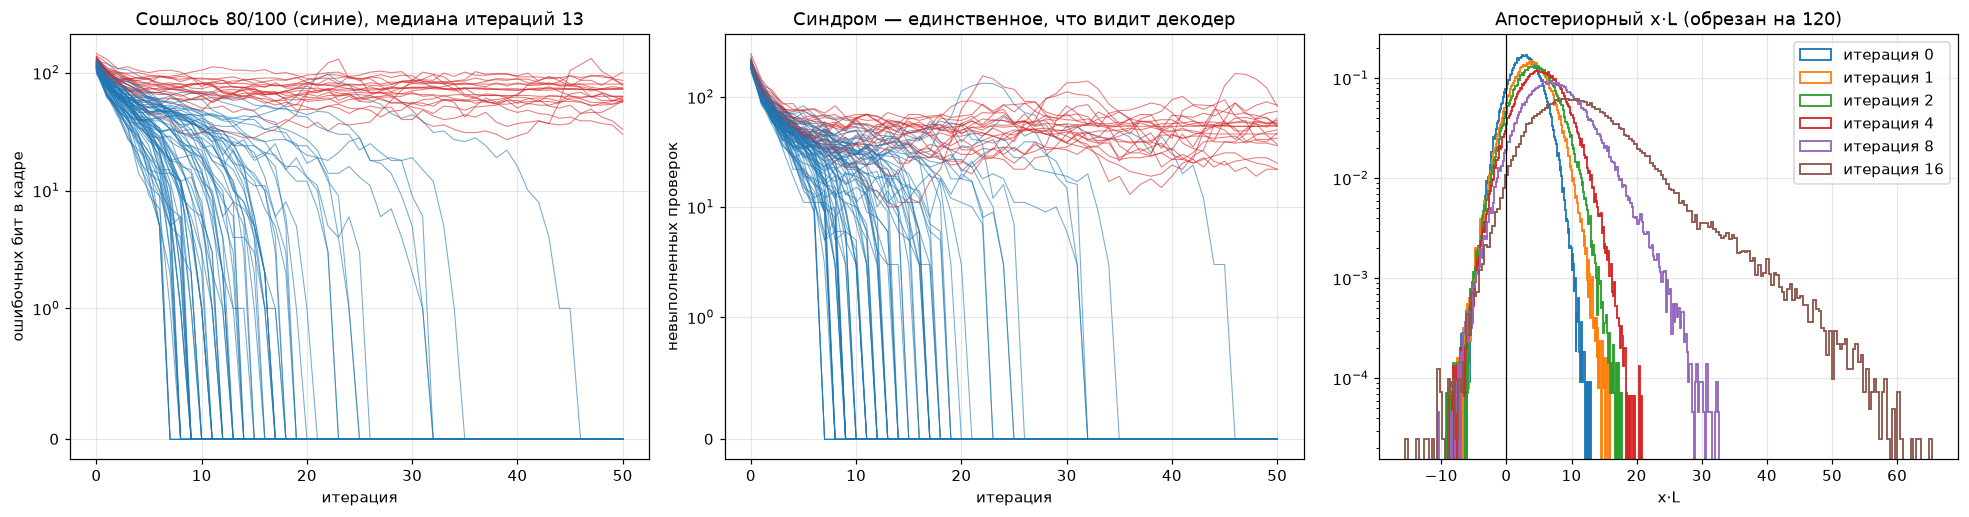

Ошибок в канале (до декодера): 117 бит на кадр из 1008 (11.6%)
После декодера: BER = 1.24e-02, FER = 0.20


In [14]:
F = 100
U = rng.integers(0, 2, (F, code.k))
C = code.encode(U); X = 1 - 2.0 * C; Xe = X[:, code.ev]
_, L, _ = channel(C, EBN0_DB, code.R, rng)
hist = []
def rec(it, Lv, Lcv):
    hist.append(dict(xL=(Lv * X).astype(np.float32), err=(Lv * X < 0).sum(1),
                     Icv=mi(Lcv, Xe), Ivc=mi(Lv[:, code.ev] - Lcv, Xe),
                     unsat=((Lv < 0).astype(np.float32) @ code.Hf.T % 2).sum(1),
                     msg=((Lv[:, code.ev] - Lcv) * Xe, Lcv * Xe) if it in (1, 3, 6) else None))
Ch, nit = code.decode(L, MAX_ITER, "spa", cb=rec)
conv = code.syndrome_ok(Ch)
E = np.array([h["err"] for h in hist])

US = np.array([h["unsat"] for h in hist])
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for f in range(F):
    ax[0].plot(E[:, f], color="C0" if conv[f] else "C3", lw=0.7, alpha=0.6)
    ax[1].plot(US[:, f], color="C0" if conv[f] else "C3", lw=0.7, alpha=0.6)
ax[1].set_yscale("symlog", linthresh=1); ax[1].set_xlabel("итерация"); ax[1].set_ylabel("невыполненных проверок")
ax[1].set_title("Синдром — единственное, что видит декодер")
ax[0].set_yscale("symlog", linthresh=1); ax[0].set_xlabel("итерация"); ax[0].set_ylabel("ошибочных бит в кадре")
ax[0].set_title(f"Сошлось {conv.sum()}/{F} (синие), медиана итераций {np.median(nit[conv]):.0f}")
for it in [0, 1, 2, 4, 8, 16]:
    if it < len(hist):
        ax[2].hist(np.clip(hist[it]["xL"].ravel(), -20, 120), 200, density=True, histtype="step", lw=1.2, label=f"итерация {it}")
ax[2].set_yscale("log"); ax[2].axvline(0, color="k", lw=0.8); ax[2].legend()
ax[2].set_title("Апостериорный x·L (обрезан на 120)"); ax[2].set_xlabel("x·L")
plt.tight_layout(); plt.show()

print(f"Ошибок в канале (до декодера): {E[0].mean():.0f} бит на кадр из {code.n} ({E[0].mean()/code.n:.1%})")
print(f"После декодера: BER = {np.mean(Ch[:, code.info] != U):.2e}, FER = {1 - conv.mean():.2f}")

## 11. Гауссово приближение и J-функция
Чтобы предсказать поведение декодера без симуляции, описывают распределение сообщений **одним числом**. Если LLR $\sim\mathcal N(\sigma^2/2,\;\sigma^2)$ (условие симметрии из раздела 5), то вся информация о бите в нём —
$$J(\sigma)=1-\mathbb E\big[\log_2(1+e^{-L})\big],\qquad L\sim\mathcal N(\sigma^2/2,\sigma^2),$$
монотонная функция от 0 (σ=0, ничего не знаем) до 1 (σ→∞). В примитивах $J$ табулирована квадратурой Гаусса–Эрмита, $J^{-1}$ — обратной интерполяцией.

**Почему через σ удобно.** Узел-бит складывает независимые LLR → складываются средние и дисперсии, т.е. $\sigma^2$. Поэтому $I_\text{out}=J\big(\sqrt{\textstyle\sum\sigma_i^2}\big)=J\big(\sqrt{\sum J^{-1}(I_i)^2}\big)$ — точная формула при гауссовых входах.

Слева — $J(\sigma)$ и проверка Монте-Карло. Справа — реальные сообщения из раздела 10 на итерации 3: бит→проверке (сумма нескольких LLR) **близки** к гауссиане $\mathcal N(\mu,2\mu)$; проверка→биту — нет (острый пик у нуля и тяжёлые хвосты, результат ⊞). Поэтому формула для узла-проверки в EXIT — лишь аппроксимация, и гауссов порог отличается от точного на несколько сотых дБ (раздел 13).

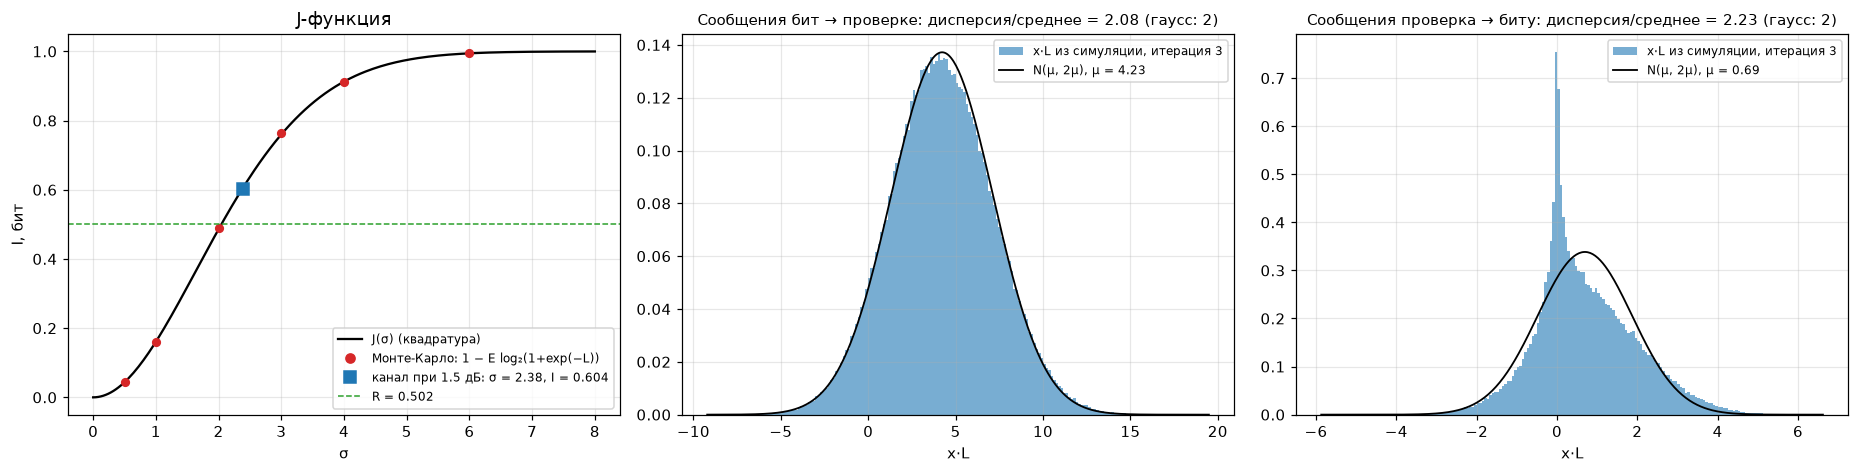

In [15]:
sg = np.linspace(0, 8, 200)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].plot(sg, J(sg), "k", label="J(σ) (квадратура)")
for s_ in [0.5, 1, 2, 3, 4, 6]:
    Ls = rng.normal(s_ ** 2 / 2, s_, 200000)
    ax[0].plot(s_, mi(Ls, 1), "C3o", ms=5)
ax[0].plot([], [], "C3o", label="Монте-Карло: 1 − E log₂(1+exp(−L))")
s_ch = sch(EBN0_DB, code.R)
ax[0].plot(s_ch, J(s_ch), "C0s", ms=8, label=f"канал при {EBN0_DB} дБ: σ = {s_ch:.2f}, I = {J(s_ch):.3f}")
ax[0].axhline(code.R, color="C2", ls="--", lw=1, label=f"R = {code.R:.3f}")
ax[0].set_xlabel("σ"); ax[0].set_ylabel("I, бит"); ax[0].legend(fontsize=8); ax[0].set_title("J-функция")
for a, k, name in [(ax[1], 0, "бит → проверке"), (ax[2], 1, "проверка → биту")]:
    d = hist[3]["msg"][k].ravel()
    d = d[np.abs(d) < 40]
    m_ = d.mean()
    a.hist(d, 200, density=True, alpha=0.6, label="x·L из симуляции, итерация 3")
    lz = np.linspace(d.min(), d.max(), 400)
    a.plot(lz, np.exp(-(lz - m_) ** 2 / (4 * m_)) / np.sqrt(4 * np.pi * m_), "k", lw=1.2, label=f"N(μ, 2μ), μ = {m_:.2f}")
    a.set_title(f"Сообщения {name}: дисперсия/среднее = {d.var() / m_:.2f} (гаусс: 2)", fontsize=10); a.legend(fontsize=8); a.set_xlabel("x·L")
plt.tight_layout(); plt.show()

## 12. Порог: EXIT-диаграмма
Если сообщения на рёбрах — гауссовы LLR, каждое описывается одним числом — взаимной информацией $I$ с битом. Узел-бит и узел-проверка — это две передаточные функции $I_\text{вых}=f(I_\text{вх})$; декодер ходит между ними «лесенкой».

- **Узел-бит**: LLR складываются, складываются и их дисперсии: $I_{E,V}=J\big(\sqrt{(d_v-1)\,J^{-1}(I_A)^2+\sigma_\text{ch}^2}\big)$. От канала зависит **только эта кривая**.
- **Узел-проверка**: $I_{E,C}\approx1-J\big(\sqrt{d_c-1}\,J^{-1}(1-I_A)\big)$.

Пока между кривыми есть **туннель**, лесенка доходит до $I=1$ (безошибочно при $n\to\infty$). Порог — $E_b/N_0$, при котором туннель смыкается. Слева — ниже порога, справа — рабочая точка; точки — измеренные в симуляции раздела 10. Первые шаги симуляция повторяет теорию, дальше отстаёт: на конечном графе через 3–4 итерации окрестность бита замыкается в циклы (обхват 6–8, раздел 3), сообщения перестают быть независимыми, а несошедшиеся кадры тянут среднее вниз.

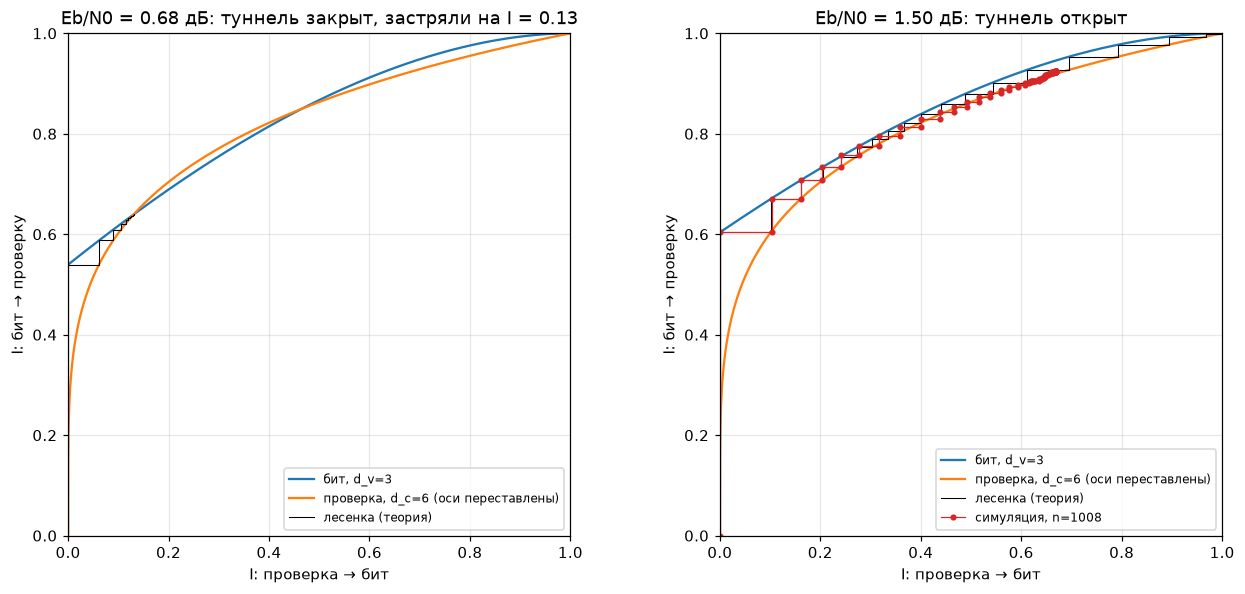

Порог по EXIT: 1.08 дБ (по точной плотностной эволюции для (3,6): 1.11 дБ), Шеннон: 0.20 дБ — регулярный код теряет 0.9 дБ; нерегулярные распределения степеней подгоняют кривые друг к другу.


In [16]:
def stairs(Ic, Iv):
    xs, ys = [Ic[0]], [0.0]
    for l in range(len(Iv)):
        xs += [Ic[l], Ic[l + 1]]; ys += [Iv[l], Iv[l]]
    return xs, ys

Ia = np.linspace(0, 1, 401)
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
for a, e in zip(ax, [TH - 0.4, EBN0_DB]):
    a.plot(Ia, exit_v(Ia, e, code.R), "C0", lw=1.5, label=f"бит, d_v={DV}")
    a.plot(exit_c(Ia), Ia, "C1", lw=1.5, label=f"проверка, d_c={DC} (оси переставлены)")
    Ic, Iv = de_traj(e, code.R, 300)
    a.plot(*stairs(Ic, Iv), "k", lw=0.7, label="лесенка (теория)")
    st = "открыт" if Ic[-1] > 0.9999 else f"закрыт, застряли на I = {Ic[-1]:.2f}"
    a.set_title(f"Eb/N0 = {e:.2f} дБ: туннель {st}")
    a.set_xlabel("I: проверка → бит"); a.set_ylabel("I: бит → проверку"); a.set_xlim(0, 1); a.set_ylim(0, 1); a.set_aspect("equal")
Icv, Ivc = np.array([h["Icv"] for h in hist]), np.array([h["Ivc"] for h in hist])
ax[1].plot(*stairs(Icv, Ivc[:-1]), "C3o-", ms=3, lw=0.8, label="симуляция, n=%d" % code.n)
for a in ax: a.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

print(f"Порог по EXIT: {TH:.2f} дБ (по точной плотностной эволюции для (3,6): 1.11 дБ), Шеннон: {SH:.2f} дБ — "
      f"регулярный код теряет {TH - SH:.1f} дБ; нерегулярные распределения степеней подгоняют кривые друг к другу.")

## 13. Плотностная эволюция Монте-Карло
EXIT предполагает гауссовость всех сообщений. Точнее — отслеживать **само распределение** сообщений (density evolution, Richardson–Urbanke). При $n\to\infty$ граф локально — дерево, и все сообщения одной итерации одинаково распределены и независимы. Распределение представим **популяцией** из $N$ выборок и будем применять к ней правила узлов, выбирая входы случайно из популяции:

1. старт: $L_\text{ch}\sim\mathcal N(\mu,2\mu)$ (передано слово из нулей — раздел 4), $L_{c\to v}=0$;
2. узел-бит: $L_{v\to c}=L_\text{ch}+\sum_{d_v-1}L_{c\to v}$ (случайные выборки);
3. узел-проверка: $L_{c\to v}=\boxplus_{d_c-1}L_{v\to c}$;
4. вероятность ошибки бита $P_e=P\big(L_\text{ch}+\sum_{d_v}L_{c\to v}<0\big)$.

Выше порога $P_e\to0$; ниже — застревает на **ненулевой неподвижной точке**: чем ближе к порогу, тем дольше «плато» (бутылочное горлышко между кривыми EXIT). Порог ищем бисекцией.

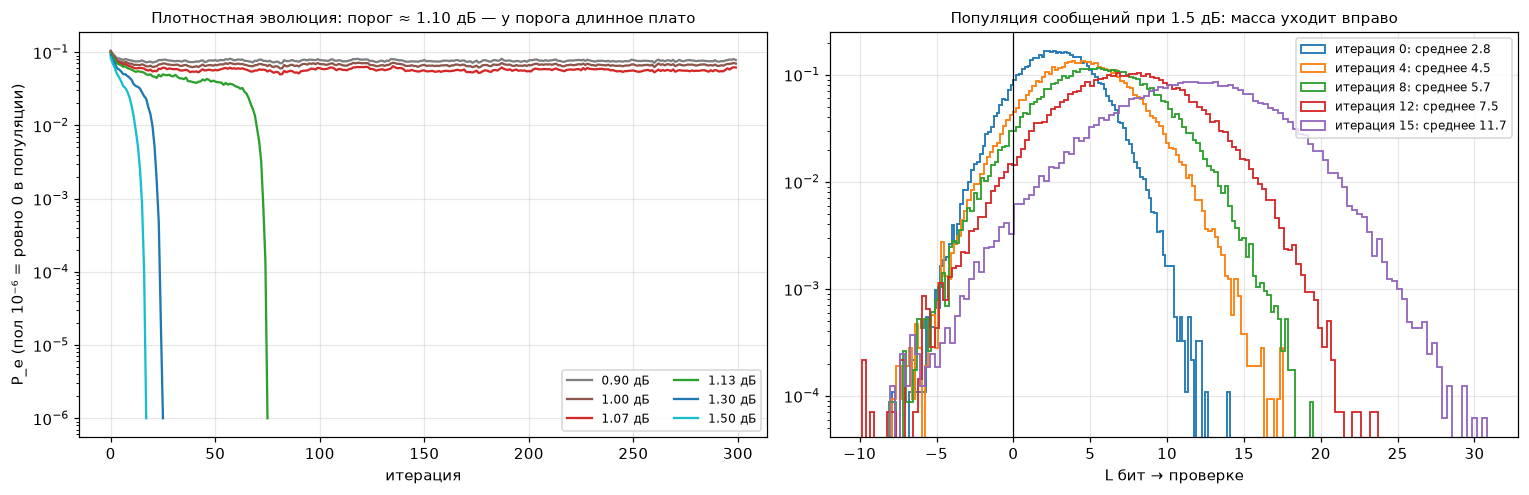

Порог (3,6): плотностная эволюция 1.10 дБ (литература 1.11), гауссов EXIT 1.08 дБ, Шеннон 0.20 дБ


In [17]:
def de_mc(e, iters=300, N=50000, seed=0, keep=()):
    r_ = np.random.default_rng(seed)
    mu_ = 4 * code.R * 10 ** (e / 10)              # μ = 2/σ² = 4R·Eb/N0
    Lc = r_.normal(mu_, np.sqrt(2 * mu_), N)
    Lcv, pe, snap = np.zeros(N), [], {}
    for it in range(iters):
        Lvc = Lc + Lcv[r_.integers(0, N, (DV - 1, N))].sum(0)
        if it in keep: snap[it] = Lvc.copy()
        Lcv = boxplus(*Lvc[r_.integers(0, N, (DC - 1, N))])
        Lp = Lc + Lcv[r_.integers(0, N, (DV, N))].sum(0)
        pe.append(np.mean(Lp < 0))
        if pe[-1] == 0: break
    return np.array(pe), snap

lo, hi = 0.8, 1.4
for _ in range(6):
    mid = (lo + hi) / 2
    lo, hi = (lo, mid) if de_mc(mid)[0][-1] < 1e-4 else (mid, hi)
TH_DE = hi

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for e, col in zip([0.9, 1.0, TH_DE - 0.03, TH_DE + 0.03, 1.3, EBN0_DB], ["C7", "C5", "C3", "C2", "C0", "C9"]):
    pe, _ = de_mc(e)
    ax[0].semilogy(np.maximum(pe, 1e-6), col, label=f"{e:.2f} дБ")
ax[0].set_xlabel("итерация"); ax[0].set_ylabel("P_e (пол 10⁻⁶ = ровно 0 в популяции)"); ax[0].legend(fontsize=8, ncol=2)
ax[0].set_title(f"Плотностная эволюция: порог ≈ {TH_DE:.2f} дБ — у порога длинное плато", fontsize=10)
_, snap = de_mc(EBN0_DB, keep=(0, 4, 8, 12, 15))
for it, d in snap.items():
    d = d[np.abs(d) < 80]
    ax[1].hist(d, 120, density=True, histtype="step", lw=1.2, label=f"итерация {it}: среднее {d.mean():.1f}")
ax[1].set_yscale("log"); ax[1].axvline(0, color="k", lw=0.8); ax[1].legend(fontsize=8); ax[1].set_xlabel("L бит → проверке")
ax[1].set_title(f"Популяция сообщений при {EBN0_DB} дБ: масса уходит вправо", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Порог (3,6): плотностная эволюция {TH_DE:.2f} дБ (литература 1.11), гауссов EXIT {TH:.2f} дБ, Шеннон {SH:.2f} дБ")

## 14. Расписание декодера: flooding против layered
В разделе 10 декодер работает по **flooding**-расписанию: все проверки обновляются одновременно по сообщениям прошлой итерации. **Layered** (послойное): проверки разбиты на слои без общих бит; после обработки слоя апостериорные LLR его бит сразу обновляются, и следующий слой уже видит свежую информацию:
$$L_{v\to c}=L_v-L_{c\to v}^\text{old},\qquad L_{c\to v}^\text{new}=\boxplus(\dots),\qquad L_v\leftarrow L_{v\to c}+L_{c\to v}^\text{new}.$$
Это то же правило Гаусса–Зейделя против Якоби в итерационных методах: информация распространяется быстрее, итераций нужно примерно вдвое меньше. Память тоже экономится — хранится только $L_v$ и $L_{c\to v}$. В железе 5G NR и Wi-Fi слой = блок-строка квазициклической матрицы.

flood   : FER = 0.233, BER = 1.4e-02, итераций у сошедшихся: среднее 15.0, медиана 13


layered : FER = 0.185, BER = 1.2e-02, итераций у сошедшихся: среднее 9.1, медиана 7


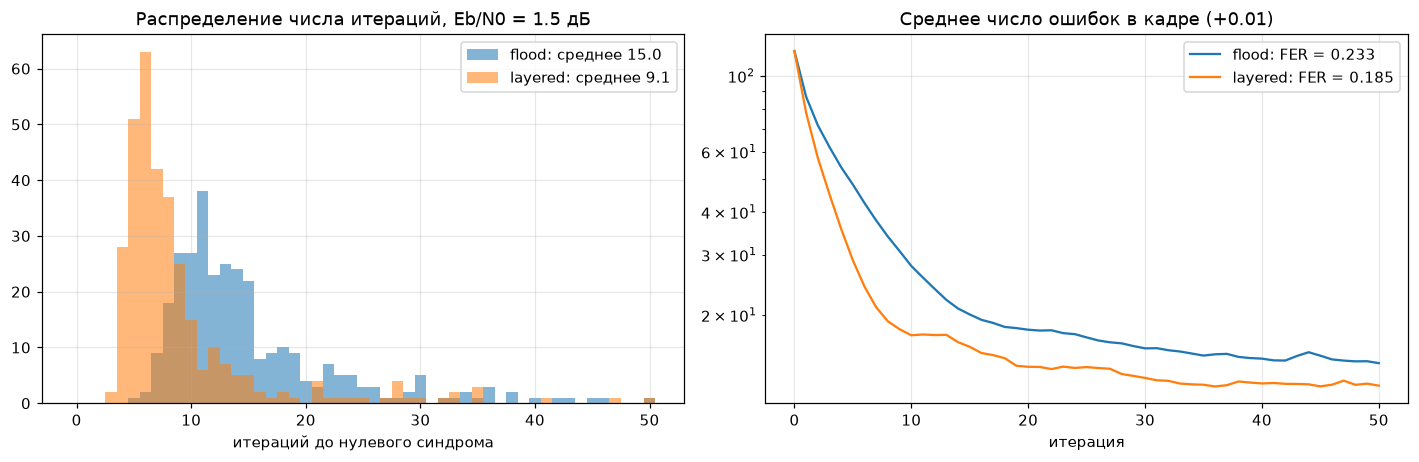

In [18]:
F14 = 400
U = rng.integers(0, 2, (F14, code.k)); C = code.encode(U); X = 1 - 2.0 * C
_, L14, _ = channel(C, EBN0_DB, code.R, rng)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for sch_, col in [("flood", "C0"), ("layered", "C1")]:
    tr = []
    Ch, nit = code.decode(L14, MAX_ITER, "spa", schedule=sch_, cb=lambda it, Lv, Lcv: tr.append((Lv * X < 0).sum(1).mean()))
    ok = code.syndrome_ok(Ch)
    ax[0].hist(nit[ok], np.arange(0, MAX_ITER + 2) - 0.5, alpha=0.55, color=col, label=f"{sch_}: среднее {nit[ok].mean():.1f}")
    ax[1].semilogy(np.array(tr) + 0.01, col, label=f"{sch_}: FER = {1 - ok.mean():.3f}")
    print(f"{sch_:8s}: FER = {1 - ok.mean():.3f}, BER = {np.mean(Ch[:, code.info] != U):.1e}, итераций у сошедшихся: среднее {nit[ok].mean():.1f}, медиана {np.median(nit[ok]):.0f}")
ax[0].set_xlabel("итераций до нулевого синдрома"); ax[0].set_title(f"Распределение числа итераций, Eb/N0 = {EBN0_DB} дБ"); ax[0].legend()
ax[1].set_xlabel("итерация"); ax[1].set_title("Среднее число ошибок в кадре (+0.01)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 15. Водопад: BER/FER против Eb/N0
Sum-product (точный BP), нормированный min-sum (то, что ставят в железо: только сравнения и сложения) и **жёсткий bit-flipping** Галлагера: декодер видит только знаки $y$ и на каждой итерации переворачивает биты, у которых больше всего невыполненных проверок. Разница между ним и BP — цена выбрасывания «мягкой» информации ($|L|$). Пунктир — предел Шеннона и EXIT-порог: порог — асимптота при $n\to\infty$, на конечной длине водопад сдвинут вправо. Справа — средняя длительность декодирования: выше по SNR декодер сходится за несколько итераций.

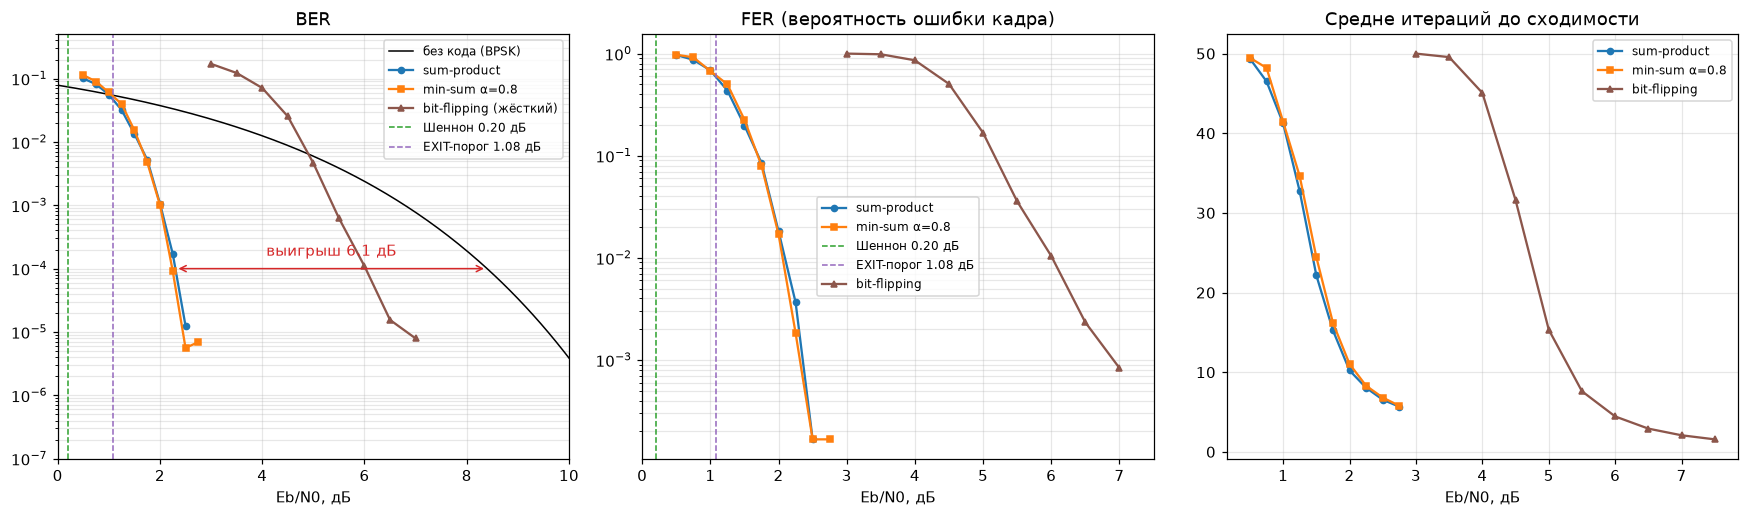

 Eb/N0 |  BER SPA   FER SPA  итер |  BER MS    FER MS   итер | кадров SPA
  0.50 |  1.0e-01  9.7e-01  49.4 |  1.1e-01  9.7e-01  49.5 | 200
  0.75 |  8.1e-02  8.7e-01  46.5 |  9.0e-02  9.2e-01  48.2 | 200
  1.00 |  5.6e-02  6.9e-01  41.2 |  6.0e-02  6.8e-01  41.4 | 200
  1.25 |  3.2e-02  4.3e-01  32.7 |  4.0e-02  5.0e-01  34.6 | 200
  1.50 |  1.3e-02  2.0e-01  22.2 |  1.5e-02  2.3e-01  24.4 | 400
  1.75 |  5.3e-03  8.5e-02  15.3 |  4.8e-03  8.0e-02  16.2 | 800
  2.00 |  1.1e-03  1.8e-02  10.2 |  1.0e-03  1.7e-02  11.0 | 2800
  2.25 |  1.7e-04  3.7e-03   8.0 |  9.2e-05  1.8e-03   8.3 | 6000
  2.50 |  1.3e-05  1.7e-04   6.5 |  5.6e-06  1.7e-04   6.8 | 6000
  2.75 |  0.0e+00  0.0e+00   5.7 |  6.9e-06  1.7e-04   5.8 | 6000

BER = 1e-04: без кода 8.4 дБ, LDPC 2.3 дБ → выигрыш кодирования 6.1 дБ ценой удвоения полосы (R = 1/2)
bit-flipping: BER = 1e-04 при 6.0 дБ → мягкие решения (BP) выигрывают 3.7 дБ у жёстких на том же коде


In [19]:
def simulate(ebn0_list, algo, min_fe=50, max_frames=6000, batch=200):
    res = []
    for e in ebn0_list:
        be = fe = nf = its = 0
        while fe < min_fe and nf < max_frames:
            U = rng.integers(0, 2, (batch, code.k))
            _, L, _ = channel(code.encode(U), e, code.R, rng)
            Ch, nit = code.bitflip(L, MAX_ITER) if algo == "bf" else code.decode(L, MAX_ITER, algo, ALPHA_MS)
            err = Ch[:, code.info] != U
            be += err.sum(); fe += err.any(1).sum(); nf += batch; its += nit.sum()
        res.append((be / (nf * code.k), fe / nf, its / nf, nf))
    return np.array(res)

ebn0 = np.arange(0.5, 2.76, 0.25)
res = {"sum-product": simulate(ebn0, "spa"), f"min-sum α={ALPHA_MS}": simulate(ebn0, "ms")}
ebn0_bf = np.arange(3.0, 7.6, 0.5)
res_bf = simulate(ebn0_bf, "bf")

r = res["sum-product"]
target = 1e-4                                      # ниже статистики мало (0 ошибок на 6000 кадров ≠ BER 0)
i = np.argmax((r[:, 0] < target) & (r[:, 0] > 0))  # первая ненулевая точка ниже цели, интерполяция по log BER
e_code = np.interp(np.log10(target), np.log10(r[[i, i - 1], 0]), ebn0[[i, i - 1]])
e_unc = brentq(lambda e: 0.5 * erfc(np.sqrt(10 ** (e / 10))) - target, 0, 15)

eb = np.linspace(0, 10, 200)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].semilogy(eb, 0.5 * erfc(np.sqrt(10 ** (eb / 10))), "k-", lw=1, label="без кода (BPSK)")
for (name, rr), mk in zip(res.items(), "os"):
    ok = rr[:, 0] > 0
    ax[0].semilogy(ebn0[ok], rr[ok, 0], mk + "-", ms=4, label=name)
    ax[1].semilogy(ebn0[rr[:, 1] > 0], rr[rr[:, 1] > 0, 1], mk + "-", ms=4, label=name)
    ax[2].plot(ebn0, rr[:, 2], mk + "-", ms=4, label=name)
okb = res_bf[:, 0] > 0
ax[0].semilogy(ebn0_bf[okb], res_bf[okb, 0], "^-", ms=4, color="C5", label="bit-flipping (жёсткий)")
for a in ax[:2]:
    a.axvline(SH, color="C2", ls="--", lw=1, label=f"Шеннон {SH:.2f} дБ")
    a.axvline(TH, color="C4", ls="--", lw=1, label=f"EXIT-порог {TH:.2f} дБ")
ax[0].annotate("", xy=(e_code, target), xytext=(e_unc, target), arrowprops=dict(arrowstyle="<->", color="C3"))
ax[0].text((e_code + e_unc) / 2, target * 1.6, f"выигрыш {e_unc - e_code:.1f} дБ", color="C3", ha="center")
ax[0].set_xlim(0, 10); ax[0].set_ylim(1e-7, 0.5)
ax[1].semilogy(ebn0_bf[res_bf[:, 1] > 0], res_bf[res_bf[:, 1] > 0, 1], "^-", ms=4, color="C5", label="bit-flipping")
ax[2].plot(ebn0_bf, res_bf[:, 2], "^-", ms=4, color="C5", label="bit-flipping")
ax[1].set_xlim(0, 7.5)
ax[0].set_title("BER"); ax[1].set_title("FER (вероятность ошибки кадра)"); ax[2].set_title("Средне итераций до сходимости")
for a in ax: a.set_xlabel("Eb/N0, дБ"); a.legend(fontsize=8); a.grid(which="both", alpha=0.3)
plt.tight_layout(); plt.show()

print(" Eb/N0 |  BER SPA   FER SPA  итер |  BER MS    FER MS   итер | кадров SPA")
for i, e in enumerate(ebn0):
    s, q = list(res.values())[0][i], list(res.values())[1][i]
    print(f" {e:5.2f} | {s[0]:8.1e} {s[1]:8.1e} {s[2]:5.1f} | {q[0]:8.1e} {q[1]:8.1e} {q[2]:5.1f} | {int(s[3])}")

print(f"\nBER = {target:.0e}: без кода {e_unc:.1f} дБ, LDPC {e_code:.1f} дБ → выигрыш кодирования {e_unc - e_code:.1f} дБ "
      f"ценой удвоения полосы (R = 1/2)")

i = np.argmax((res_bf[:, 0] < target) & (res_bf[:, 0] > 0))
e_bf = np.interp(np.log10(target), np.log10(res_bf[[i, i - 1], 0]), ebn0_bf[[i, i - 1]]) if i > 0 else np.nan
print(f"bit-flipping: BER = {target:.0e} при {e_bf:.1f} дБ → мягкие решения (BP) выигрывают {e_bf - e_code:.1f} дБ у жёстких на том же коде")

## 16. Длина кода и нормировка min-sum
**Длина.** Порог (раздел 12–13) — свойство ансамбля $(d_v,d_c)$ при $n\to\infty$. Конечный код отличается двумя вещами: (1) случайная реализация шума в $n$ символах флуктуирует вокруг среднего, и при коротком $n$ чаще выпадает «плохой» кадр — водопад пологий; (2) циклы короче, сообщения коррелированы. С ростом $n$ водопад становится круче и прижимается к порогу, но не переходит его. Для каждой длины строим свой код той же конструкцией; на точку не больше 2000 кадров, так что FER ниже ~$10^{-3}$ — это единичные ошибки (а нулевые точки не рисуются).

**Нормировка.** FER min-sum в зависимости от $\alpha$ при двух $E_b/N_0$; горизонтальные линии — точный sum-product. При $\alpha=1$ проверки переоценивают уверенность (раздел 6) — ошибочные сообщения слишком «громкие». При слишком малом $\alpha$ — наоборот, правильные сообщения недооценены, сходимость медленная.

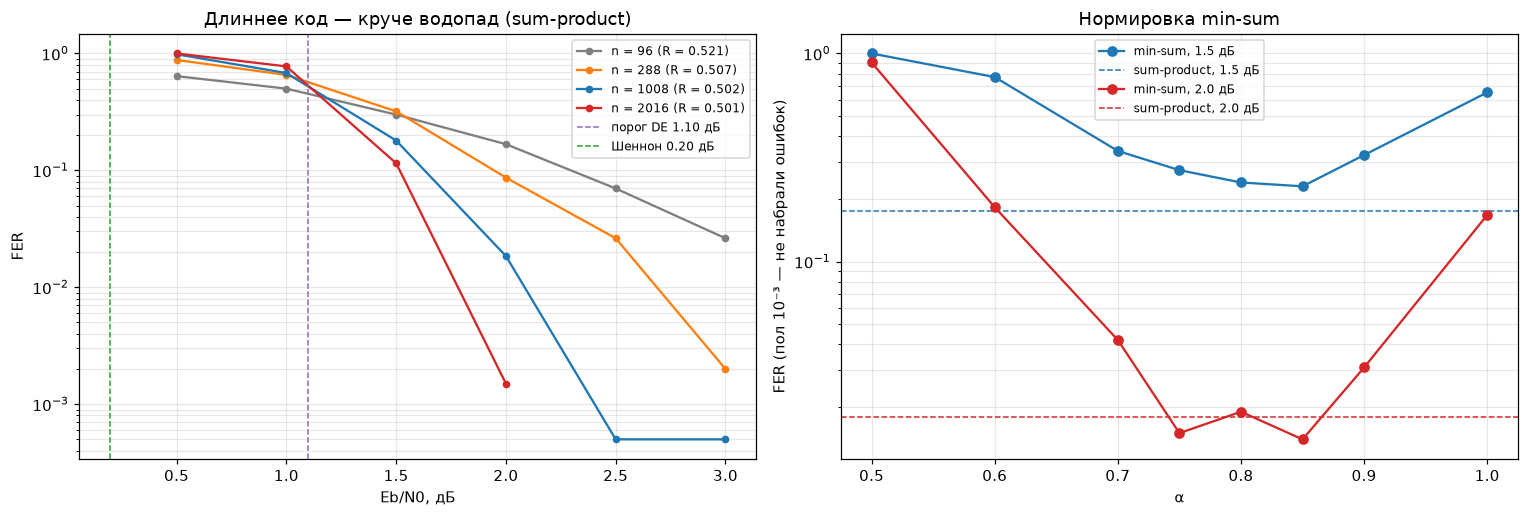

FER по длинам:
  Eb/N0       n=96     n=288    n=1008    n=2016
   0.50   6.40e-01  8.80e-01  9.85e-01  1.00e+00
   1.00   5.00e-01  6.55e-01  6.80e-01  7.75e-01
   1.50   3.00e-01  3.20e-01  1.80e-01  1.15e-01
   2.00   1.68e-01  8.67e-02  1.85e-02  1.50e-03
   2.50   7.00e-02  2.62e-02  5.00e-04  0.00e+00
   3.00   2.62e-02  2.00e-03  5.00e-04  0.00e+00
1.5 дБ: лучшее α = 0.85, FER min-sum 0.230 против sum-product 0.175, α=1: 0.650
2.0 дБ: лучшее α = 0.85, FER min-sum 0.014 против sum-product 0.018, α=1: 0.168


In [20]:
def sim_fer(cd, e, algo="spa", alpha=ALPHA_MS, min_fe=40, max_frames=2000, batch=200):
    fe = nf = 0
    while fe < min_fe and nf < max_frames:
        U = rng.integers(0, 2, (batch, cd.k))
        _, L, _ = channel(cd.encode(U), e, cd.R, rng)
        Ch, _ = cd.decode(L, MAX_ITER, algo, alpha)
        fe += (Ch[:, cd.info] != U).any(1).sum(); nf += batch
    return fe / nf

lens = [96, 288, N_CODE, 2016]
codes = {n_: (code if n_ == N_CODE else LDPC(gallager_H(n_, DV, DC, np.random.default_rng(SEED)))) for n_ in lens}
eb16 = np.arange(0.5, 3.01, 0.5)
fer_n = {n_: np.array([sim_fer(cd, e) for e in eb16]) for n_, cd in codes.items()}

alphas = np.array([0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 1.0])
eb_a = [1.5, 2.0]
fer_a = {e: np.array([sim_fer(code, e, "ms", a_, max_frames=1000) for a_ in alphas]) for e in eb_a}
fer_spa = {e: sim_fer(code, e, "spa", max_frames=1000) for e in eb_a}

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for n_, col in zip(lens, ["C7", "C1", "C0", "C3"]):
    f_ = fer_n[n_]; ok = f_ > 0
    ax[0].semilogy(eb16[ok], f_[ok], "o-", ms=4, color=col, label=f"n = {n_} (R = {codes[n_].R:.3f})")
ax[0].axvline(TH_DE, color="C4", ls="--", lw=1, label=f"порог DE {TH_DE:.2f} дБ"); ax[0].axvline(SH, color="C2", ls="--", lw=1, label=f"Шеннон {SH:.2f} дБ")
ax[0].set_xlabel("Eb/N0, дБ"); ax[0].set_ylabel("FER"); ax[0].legend(fontsize=8); ax[0].set_title("Длиннее код — круче водопад (sum-product)")
ax[0].grid(which="both", alpha=0.3)
for e, col in zip(eb_a, ["C0", "C3"]):
    ax[1].semilogy(alphas, np.maximum(fer_a[e], 1e-3), "o-", color=col, label=f"min-sum, {e} дБ")
    ax[1].axhline(max(fer_spa[e], 1e-3), color=col, ls="--", lw=1, label=f"sum-product, {e} дБ")
ax[1].set_xlabel("α"); ax[1].set_ylabel("FER (пол 10⁻³ — не набрали ошибок)"); ax[1].legend(fontsize=8)
ax[1].set_title("Нормировка min-sum"); ax[1].grid(which="both", alpha=0.3)
plt.tight_layout(); plt.show()

print("FER по длинам:"); print("  Eb/N0 " + "".join(f"{f'n={n_}':>10s}" for n_ in lens))
for j, e in enumerate(eb16): print(f"  {e:5.2f} " + "".join(f"{fer_n[n_][j]:10.2e}" for n_ in lens))
for e in eb_a:
    print(f"{e} дБ: лучшее α = {alphas[np.argmin(fer_a[e])]}, FER min-sum {fer_a[e].min():.3f} против sum-product {fer_spa[e]:.3f}, α=1: {fer_a[e][-1]:.3f}")

## Сравнение с CDMA
DSSS из соседнего ноутбука — это тоже код, **код повторения** со скоростью $R=1/N$: бит просто повторяется $N$ раз. Против белого шума он не даёт ничего (кривая = BPSK): энергия бита та же, просто размазана по $N$ чипам. LDPC при $R=1/2$ даёт 6–7 дБ: проверочные биты не копируют данные, а **связывают** их, и каждая ошибка должна «пробиться» через несколько независимых ограничений.

| | DSSS (повторение) | LDPC (3,6) |
|---|---|---|
| Избыточность | $N=1023$ | 2 |
| Выигрыш против AWGN (BER $10^{-4}$…$10^{-5}$) | 0 дБ | 6–7 дБ |
| Против узкополосной помехи | $10\log_{10}N$ = 30 дБ | ~0 (нужен перемежитель) |
| Декодер | один коррелятор | итеративный обмен LLR |

В реальных системах они работают вместе: спрединг/OFDM разбирается с каналом, код — с остаточным шумом. В LTE данные кодируются турбо-кодом (тот же принцип итеративного обмена LLR, два свёрточных кода вместо графа); LDPC пришёл в 5G NR и Wi-Fi — квазициклические матрицы, собранные из циклических сдвигов единичных блоков $Z\times Z$, чтобы декодер был параллельным.

## Что покрутить
- `EBN0_DB = 1.0` — ниже порога: в разделе 12 туннель закрыт, в разделе 10 почти все кадры застревают с сотней ошибок, в разделе 13 популяция застревает на плато
- `N_CODE = 96` / `4032` — водопад становится круче с длиной и прижимается к порогу, сам порог не меняется (раздел 16 показывает несколько длин сразу); при малом $n$ в разделе 3 обхват падает до 4–6
- `DV, DC = 4, 8` (та же $R=1/2$) — порог хуже (~1.5 дБ): больше рёбер — больше ограничений, но каждое слабее
- `ALPHA_MS = 1.0` — чистый min-sum переоценивает уверенность проверок ($\min|L|$ больше точного значения) и заметно проигрывает; нормировка это компенсирует. На высоком SNR нормированный min-sum бывает даже лучше точного BP: на графе с циклами BP сам «пересамоуверен»
- в `gallager_H(..., fix_4cycles=False)` — оставить 4-циклы и посмотреть на ошибочное «эхо» в BP
- в разделе 8 — `channel(c8, 2.0, ...)`: ошибок в канале больше, и на 12-битном коде с 4-циклами BP начинает «зацикливаться» — LLR осциллируют, а не растут
- в разделе 14 — `"ms"` вместо `"spa"`: layered ускоряет и min-sum; разрыв по итерациям примерно тот же
- в разделе 13 — `N=5000`: популяция мала, порог «плавает» — та же проблема конечной длины, что и у реального кода